# Uber Eats 商家流失预测：从 Feature Mart 到模型解释

我们的目标不只是“训练出一个模型”，而是建立一条从业务问题到模型结果的完整分析链路，并理解每一步解决了什么问题、如果跳过会有什么风险。

接下来我们会依次完成：

1. 从五张原始业务表构建 `merchant_id × cutoff_date` 粒度的 Feature Mart；
2. 用 EDA 检查标签、缺失值、类别不平衡和潜在的数据泄漏；
3. 使用不会泄漏验证集信息的预处理 Pipeline；
4. 比较 Dummy、Logistic Regression 和 Random Forest；
5. 用 PR-AUC、Recall@Top 5% 和 Precision@Top 5% 连接模型表现与运营容量；
6. 用系数、Permutation Importance 和 SHAP 解释模型。

> 本案例使用合成业务数据。流失定义：商家在 `cutoff_date` 之后 28 天内完成订单数为 0。

## 0. 课程目录：从原始数据到可执行的流失名单

这门课分为四个 Part，并用两节课完成。完整工作流是：

`五张原始表 → SQL Feature Mart → 数据质量与 EDA → Feature Engineering → Model-ready Data → 模型训练与评估 → 业务阈值 → 模型解释`

| Part | 主题 | 完成后我们会得到什么？ | 对应章节 |
|---|---|---|---|
| **Part 1** | **Prepare Data Signals：从原始表到 SQL Feature Mart** | 一张 grain、时间窗口和标签定义清楚的建模宽表 | 1–3 |
| **Part 2** | **Explore & Engineer Features：从数据质量与 EDA 到 Model-ready Data** | 经过质量检查、特征工程、泄漏检查和预处理设计的数据 | 1–6 |
| **Part 3** | **Train & Evaluate Models：训练、验证与模型选择** | 在统一验证口径下选出的最终候选模型 | 1–3 |
| **Part 4** | **Turn Predictions into Actions：业务阈值与模型解释** | 可执行的商家联系名单，以及能够向业务说明的模型结论 | 1–5 |

为什么顺序很重要？因为模型只能学习我们交给它的数据。如果 Feature Mart 粒度错误、标签使用了未来信息，后面再复杂的算法也只会得到一个“看起来很准、上线后失效”的模型。

In [ ]:
%pip install matplotlib seaborn imbalanced-learn

In [1]:
from pathlib import Path
import sqlite3
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    KFold,
    ParameterGrid,
    StratifiedGroupKFold,
    StratifiedKFold,
    TimeSeriesSplit,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbalancedPipeline
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

DATA_DIR = Path("data")
NOTEBOOK_OUTPUT_DIR = Path("outputs/eda_modeling_notebook")
NOTEBOOK_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


# Part 1｜Prepare Data Signals

## 从五张原始表到 SQL Feature Mart

这一部分先明确每张原始表的粒度和主键，再通过 SQL 聚合不同时间窗口的业务信号，最终生成一行一个 `merchant_id × cutoff_date` 的 Feature Mart。

## 1. 读取五张原始表

### 为什么先看原始表？

真实项目中，字段往往来自不同系统。建模前必须知道每张表的 **grain（每一行代表什么）** 和 **key（什么字段应该唯一）**。

- `merchant_dim`：一行一个商家；
- `merchant_daily_sample`：一行一个商家一天；
- `orders_sample`：一行一笔订单；
- `support_fact`：一行一张客服工单；
- `promotion_fact`：一行一次促销活动。

如果直接把订单表、客服表和促销表连接起来，可能形成 many-to-many join，导致订单金额和工单数被重复计算。因此我们会先分别聚合，再在商家与 cutoff 粒度连接。

In [2]:
# 本次分析需要读取的五张业务表。
RAW_SHEETS = {'merchant_dim': 'merchant_dim.csv', 'merchant_daily': 'merchant_daily_sample.csv', 'orders': 'orders_sample.csv', 'support': 'support_fact.csv', 'promotion': 'promotion_fact.csv'}

In [3]:
def load_raw_tables(data_dir: Path) -> dict[str, pd.DataFrame]:
    """读取 V3 的五张原始业务表；标签也由这些表现场计算。"""
    if not data_dir.is_dir():
        raise FileNotFoundError(f"V3 data directory not found: {data_dir.resolve()}")
    tables: dict[str, pd.DataFrame] = {}
    for sql_name, file_name in RAW_SHEETS.items():
        file_path = data_dir / file_name
        if not file_path.exists():
            raise FileNotFoundError(f"Missing V3 raw table: {file_path.resolve()}")
        tables[sql_name] = pd.read_csv(file_path)
    return tables

In [4]:
raw_tables = load_raw_tables(DATA_DIR)

raw_summary = pd.DataFrame([
    {
        "table": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "unique_merchants": frame["merchant_id"].nunique(),
    }
    for name, frame in raw_tables.items()
])
raw_summary

,table,rows,columns,unique_merchants
0,merchant_dim,2000,9,2000
1,merchant_daily,240000,12,2000
2,orders,105095,25,1998
3,support,5492,8,1849
4,promotion,2687,8,1494


## 2. 检查主键，再注册 SQL 表

### 为什么检查主键？

主键重复通常意味着两类问题：上游数据真的重复，或我们误解了表的粒度。无论哪一种，都会让聚合指标偏大。

这里把 Pandas DataFrame 注册到内存中的 SQLite：用 Python 控制分析流程，用 SQL 完成业务特征聚合。

In [5]:
def register_sql_tables(
    raw_tables: dict[str, pd.DataFrame],
) -> tuple[sqlite3.Connection, pd.DataFrame]:
    """检查主键并将 DataFrame 注册为 SQLite 表。"""
    key_map = {
        "merchant_dim": "merchant_id",
        "orders": "order_id",
        "support": "ticket_id",
        "promotion": "promotion_id",
    }
    key_quality = pd.DataFrame(
        [
            {
                "table": table,
                "key": key,
                "rows": len(raw_tables[table]),
                "duplicate_rows": int(raw_tables[table].duplicated(key).sum()),
            }
            for table, key in key_map.items()
        ]
    )
    non_order_duplicates = key_quality.loc[
        key_quality["table"] != "orders", "duplicate_rows"
    ]
    if non_order_duplicates.gt(0).any():
        raise ValueError("Unexpected duplicate primary keys outside orders table")

    connection = sqlite3.connect(":memory:")
    for name, dataframe in raw_tables.items():
        sql_ready = dataframe.copy()
        if name == "orders":
            sql_ready = sql_ready.drop_duplicates("order_id", keep="first")
        for column in sql_ready.columns:
            if "date" in column or column in {"created_at", "resolved_at"}:
                sql_ready[column] = pd.to_datetime(
                    sql_ready[column], errors="coerce"
                ).astype("string")
        sql_ready.to_sql(name, connection, index=False, if_exists="replace")
    return connection, key_quality

In [6]:
connection, key_quality = register_sql_tables(raw_tables)
key_quality

,table,key,rows,duplicate_rows
0,merchant_dim,merchant_id,2000,0
1,orders,order_id,105095,0
2,support,ticket_id,5492,0
3,promotion,promotion_id,2687,0


## 3. 用 SQL 构建 Feature Mart

### 一行数据代表什么？

Feature Mart 的 grain 是：

> 一个商家在一个 `cutoff_date` 时点的历史状态。

所有模型特征只能使用 cutoff 之前的数据；标签使用 cutoff 之后 28 天的数据：

- Feature window：主要观察 cutoff 前 7、28 或 30 天；
- Label window：观察 `[cutoff_date, cutoff_date + 28 days)`；
- `future_orders_28d = 0` 时，`churn_label = 1`。

下面直接展开完整 SQL。SQL 会分别聚合订单、商家日状态、客服和促销数据，再连接成 Feature Mart。课堂上可以按 `cohorts → base → 各主题聚合 → 最终 SELECT` 的顺序逐段查看。

In [7]:
# 每个 cutoff_date 都会生成一份当时可用的商家特征快照。
CUTOFF_DATES = ['2026-03-01', '2026-04-01', '2026-05-01', '2026-06-01']

In [8]:
def build_feature_mart(connection: sqlite3.Connection) -> pd.DataFrame:
    """用 SQL 构建 merchant × cutoff 粒度的 Feature Mart。"""
    cohort_sql = " UNION ALL ".join(
        f"SELECT DATE('{cutoff}') AS cutoff_date" for cutoff in CUTOFF_DATES
    )
    feature_sql = f"""
    WITH cohorts AS (
        {cohort_sql}
    ),
    base AS (
        SELECT
            m.merchant_id,
            c.cutoff_date,
            STRFTIME('%Y-%m', c.cutoff_date) AS cohort,
            m.city,
            m.cuisine_type,
            m.segment,
            m.menu_ready,
            m.competitor_presence,
            CAST(JULIANDAY(c.cutoff_date) - JULIANDAY(m.join_date) AS INTEGER)
                AS account_age_days
        FROM merchant_dim AS m
        CROSS JOIN cohorts AS c
    ),
    order_raw AS (
        SELECT
            b.merchant_id,
            b.cutoff_date,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) >= DATE(b.cutoff_date, '-7 day')
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN 1 ELSE 0 END) AS weekly_orders_7d,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) >= DATE(b.cutoff_date, '-28 day')
                      AND DATE(o.order_date) < DATE(b.cutoff_date, '-7 day')
                     THEN 1 ELSE 0 END) AS previous_orders_21d,
            MAX(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN DATE(o.order_date) END) AS last_order_date,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN 1 ELSE 0 END) AS completed_orders_28d,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN o.gross_sales ELSE 0 END) AS gmv_28d,
            COUNT(DISTINCT CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN o.customer_id END) AS unique_customers_28d,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.new_customer_flag = 1
                     THEN 1 ELSE 0 END) AS new_orders_28d,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.repeat_customer_flag = 1
                     THEN 1 ELSE 0 END) AS repeat_orders_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.accepted_flag = 1 THEN 1 ELSE 0 END)
                AS accepted_orders_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.cancelled_flag = 1 THEN 1 ELSE 0 END)
                AS cancelled_orders_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.merchant_delay_flag = 1 THEN 1 ELSE 0 END)
                AS delayed_orders_28d,
            AVG(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN o.prep_time_minutes END) AS avg_prep_28d,
            AVG(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN o.prep_time_minutes * o.prep_time_minutes END)
                AS avg_prep_sq_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.late_delivery_flag = 1 THEN 1 ELSE 0 END)
                AS late_orders_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.refund_requested_flag = 1 THEN 1 ELSE 0 END)
                AS refund_orders_28d,
            AVG(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN o.customer_rating END) AS avg_rating_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.customer_rating = 1 THEN 1 ELSE 0 END)
                AS one_star_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.customer_rating IS NOT NULL THEN 1 ELSE 0 END)
                AS rated_orders_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.complaint_flag = 1 THEN 1 ELSE 0 END)
                AS complaints_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN COALESCE(o.commission_amount, 0) ELSE 0 END)
                AS commission_paid_28d,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN COALESCE(o.merchant_profit, 0) ELSE 0 END)
                AS profit_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.merchant_dispute_flag = 1 THEN 1 ELSE 0 END)
                AS disputes_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                      AND o.payment_failed_flag = 1 THEN 1 ELSE 0 END)
                AS failed_payments_28d,
            SUM(CASE WHEN DATE(o.order_date) < DATE(b.cutoff_date)
                     THEN 1 ELSE 0 END) AS all_orders_28d,
            SUM(CASE WHEN o.completed_flag = 1
                      AND DATE(o.order_date) >= DATE(b.cutoff_date)
                      AND DATE(o.order_date) < DATE(b.cutoff_date, '+28 day')
                     THEN 1 ELSE 0 END) AS future_orders_28d
        FROM base AS b
        LEFT JOIN orders AS o
          ON b.merchant_id = o.merchant_id
         AND DATE(o.order_date) >= DATE(b.cutoff_date, '-28 day')
         AND DATE(o.order_date) < DATE(b.cutoff_date, '+28 day')
        GROUP BY b.merchant_id, b.cutoff_date
    ),
    order_features AS (
        SELECT
            *,
            CASE WHEN previous_orders_21d > 0
                 THEN (weekly_orders_7d - previous_orders_21d / 3.0)
                      / (previous_orders_21d / 3.0) END
                AS order_trend_vs_prev3w,
            CASE WHEN last_order_date IS NOT NULL
                 THEN CAST(JULIANDAY(cutoff_date) - JULIANDAY(last_order_date)
                           AS INTEGER) END AS days_since_last_order,
            gmv_28d / NULLIF(completed_orders_28d, 0) AS aov_28d,
            new_orders_28d * 1.0 / NULLIF(completed_orders_28d, 0)
                AS new_customer_ratio_28d,
            cancelled_orders_28d * 1.0 / NULLIF(accepted_orders_28d, 0)
                AS cancellation_rate_28d,
            delayed_orders_28d * 1.0 / NULLIF(completed_orders_28d, 0)
                AS merchant_delay_rate_28d,
            SQRT(MAX(avg_prep_sq_28d - avg_prep_28d * avg_prep_28d, 0))
                AS prep_time_std_28d,
            late_orders_28d * 1.0 / NULLIF(completed_orders_28d, 0)
                AS late_delivery_rate_28d,
            refund_orders_28d * 1.0 / NULLIF(all_orders_28d, 0)
                AS refund_rate_28d,
            one_star_28d * 1.0 / NULLIF(rated_orders_28d, 0)
                AS one_star_review_rate_28d,
            complaints_28d * 1.0 / NULLIF(all_orders_28d, 0)
                AS complaint_rate_28d,
            repeat_orders_28d * 1.0 / NULLIF(completed_orders_28d, 0)
                AS repeat_customer_rate_28d,
            profit_28d / NULLIF(gmv_28d, 0) AS profit_margin_28d,
            disputes_28d * 1.0 / NULLIF(all_orders_28d, 0)
                AS dispute_rate_28d,
            failed_payments_28d * 1.0 / NULLIF(all_orders_28d, 0)
                AS failed_payment_rate_28d
        FROM order_raw
    ),
    daily_features AS (
        SELECT
            b.merchant_id,
            b.cutoff_date,
            SUM(CASE WHEN d.is_open = 1 THEN 1 ELSE 0 END)
                AS store_open_days_28d,
            AVG(d.business_hours_consistency)
                AS business_hours_consistency_28d,
            SUM(CASE WHEN d.temporary_closure_flag = 1 THEN 1 ELSE 0 END)
                AS temporary_closure_days_28d
        FROM base AS b
        LEFT JOIN merchant_daily AS d
          ON b.merchant_id = d.merchant_id
         AND DATE(d.date) >= DATE(b.cutoff_date, '-28 day')
         AND DATE(d.date) < DATE(b.cutoff_date)
        GROUP BY b.merchant_id, b.cutoff_date
    ),
    support_features AS (
        SELECT
            b.merchant_id,
            b.cutoff_date,
            COUNT(s.ticket_id) AS support_ticket_count_30d,
            AVG(CASE WHEN s.resolved_flag = 1 THEN s.resolution_hours END)
                AS issue_resolution_time_hours,
            SUM(CASE WHEN s.ticket_id IS NOT NULL
                      AND COALESCE(s.resolved_flag, 0) = 0 THEN 1 ELSE 0 END)
                * 1.0 / NULLIF(COUNT(s.ticket_id), 0)
                AS unresolved_ticket_rate_30d
        FROM base AS b
        LEFT JOIN support AS s
          ON b.merchant_id = s.merchant_id
         AND DATETIME(s.created_at) >= DATETIME(b.cutoff_date, '-30 day')
         AND DATETIME(s.created_at) < DATETIME(b.cutoff_date)
        GROUP BY b.merchant_id, b.cutoff_date
    ),
    promotion_features AS (
        SELECT
            b.merchant_id,
            b.cutoff_date,
            COUNT(p.promotion_id) AS promotion_participation_30d,
            SUM(COALESCE(p.promo_spend, 0)) AS promotion_spend_30d,
            (SUM(COALESCE(p.promotion_return, 0))
             - SUM(COALESCE(p.promo_spend, 0)))
             / NULLIF(SUM(COALESCE(p.promo_spend, 0)), 0)
                AS promotion_roi_30d
        FROM base AS b
        LEFT JOIN promotion AS p
          ON b.merchant_id = p.merchant_id
         AND DATE(p.start_date) < DATE(b.cutoff_date)
         AND DATE(p.end_date) >= DATE(b.cutoff_date, '-30 day')
        GROUP BY b.merchant_id, b.cutoff_date
    )
    SELECT
        b.merchant_id, b.cutoff_date, b.cohort,
        b.city, b.cuisine_type, b.segment,
        COALESCE(o.weekly_orders_7d, 0) AS weekly_orders_7d,
        o.order_trend_vs_prev3w,
        COALESCE(o.gmv_28d, 0) AS gmv_28d,
        o.aov_28d,
        COALESCE(o.unique_customers_28d, 0) AS unique_customers_28d,
        o.new_customer_ratio_28d,
        b.menu_ready,
        COALESCE(p.promotion_participation_30d, 0)
            AS promotion_participation_30d,
        COALESCE(d.store_open_days_28d, 0) AS store_open_days_28d,
        d.business_hours_consistency_28d,
        COALESCE(d.temporary_closure_days_28d, 0)
            AS temporary_closure_days_28d,
        o.cancellation_rate_28d,
        o.merchant_delay_rate_28d,
        o.avg_prep_28d AS avg_preparation_time_28d,
        o.prep_time_std_28d,
        o.late_delivery_rate_28d,
        o.refund_rate_28d,
        o.avg_rating_28d AS average_rating_28d,
        o.one_star_review_rate_28d,
        o.complaint_rate_28d,
        o.repeat_customer_rate_28d,
        COALESCE(o.commission_paid_28d, 0) AS commission_paid_28d,
        o.profit_margin_28d,
        p.promotion_spend_30d / NULLIF(o.gmv_28d, 0)
            AS promotion_cost_ratio_30d,
        p.promotion_roi_30d,
        o.dispute_rate_28d,
        COALESCE(s.support_ticket_count_30d, 0)
            AS support_ticket_count_30d,
        s.issue_resolution_time_hours,
        s.unresolved_ticket_rate_30d,
        o.failed_payment_rate_28d,
        b.account_age_days,
        b.competitor_presence,
        o.days_since_last_order,
        COALESCE(o.future_orders_28d, 0) AS future_orders_28d,
        CASE WHEN COALESCE(o.future_orders_28d, 0) = 0 THEN 1 ELSE 0 END
            AS churn_label
    FROM base AS b
    LEFT JOIN order_features AS o
      ON b.merchant_id = o.merchant_id AND b.cutoff_date = o.cutoff_date
    LEFT JOIN daily_features AS d
      ON b.merchant_id = d.merchant_id AND b.cutoff_date = d.cutoff_date
    LEFT JOIN support_features AS s
      ON b.merchant_id = s.merchant_id AND b.cutoff_date = s.cutoff_date
    LEFT JOIN promotion_features AS p
      ON b.merchant_id = p.merchant_id AND b.cutoff_date = p.cutoff_date
    ORDER BY b.cutoff_date, b.merchant_id
    """
    feature_mart = pd.read_sql_query(feature_sql, connection)
    feature_mart["cutoff_date"] = pd.to_datetime(feature_mart["cutoff_date"])
    return feature_mart

In [9]:
try:
    feature_mart = build_feature_mart(connection)
finally:
    connection.close()

print("Feature Mart shape:", feature_mart.shape)
feature_mart.head()

Feature Mart shape: (8000, 41)


,merchant_id,cutoff_date,cohort,city,cuisine_type,segment,weekly_orders_7d,order_trend_vs_prev3w,gmv_28d,aov_28d,unique_customers_28d,new_customer_ratio_28d,menu_ready,promotion_participation_30d,store_open_days_28d,business_hours_consistency_28d,temporary_closure_days_28d,cancellation_rate_28d,merchant_delay_rate_28d,avg_preparation_time_28d,prep_time_std_28d,late_delivery_rate_28d,refund_rate_28d,average_rating_28d,one_star_review_rate_28d,complaint_rate_28d,repeat_customer_rate_28d,commission_paid_28d,profit_margin_28d,promotion_cost_ratio_30d,promotion_roi_30d,dispute_rate_28d,support_ticket_count_30d,issue_resolution_time_hours,unresolved_ticket_rate_30d,failed_payment_rate_28d,account_age_days,competitor_presence,days_since_last_order,future_orders_28d,churn_label
0,M00001,2026-03-01,2026-03,Oakland,Mexican,SMB,3,2.000,130.940,21.823,6,0.167,1,0,23,0.717,4,0.000,0.167,18.765,5.170,0.000,0.000,4.667,0.000,0.000,0.833,33.270,0.183,0.000,NaN,0.000,0,NaN,NaN,0.000,559,0,1.000,3,0
1,M00002,2026-03-01,2026-03,San Jose,American,SMB,0,-1.000,125.430,25.086,5,0.000,1,0,24,0.692,3,0.000,0.200,24.228,3.335,0.000,0.000,3.800,0.000,0.000,1.000,29.670,0.310,0.000,NaN,0.000,1,26.350,0.000,0.000,599,0,11.000,6,0
2,M00003,2026-03-01,2026-03,San Francisco,Italian,SMB,2,2.000,119.210,29.803,4,0.750,1,0,22,0.616,2,0.000,0.000,24.785,1.808,0.000,0.000,4.750,0.000,0.250,0.250,30.870,0.142,0.000,NaN,0.000,0,NaN,NaN,0.000,796,1,1.000,5,0
3,M00004,2026-03-01,2026-03,Oakland,Japanese,Mid-Market,9,0.800,529.380,22.058,24,0.500,1,0,25,0.728,2,0.000,0.000,21.561,5.538,0.125,0.000,4.125,0.000,0.000,0.500,137.670,0.172,0.000,NaN,0.083,0,NaN,NaN,0.000,1822,1,1.000,11,0
4,M00005,2026-03-01,2026-03,San Francisco,Thai,SMB,2,2.000,104.790,26.197,4,0.250,1,0,25,0.752,2,0.000,0.000,21.008,6.583,0.000,0.250,4.750,0.000,0.000,0.750,27.250,0.187,0.000,NaN,0.000,0,NaN,NaN,0.000,1089,0,3.000,6,0


# Part 2｜Explore & Engineer Features

## 从数据质量与 EDA 到 Model-ready Data

Feature Mart 建好后不能直接训练模型。我们需要检查 Y、缺失值、异常值和类别分布，理解特征与流失的关系，完成必要的 Feature Engineering，并设计不会产生数据泄漏的切分与预处理流程。

### 开始分析前，先明确检查顺序

EDA 的全称是 **Exploratory Data Analysis（探索性数据分析）**。它不是“画几张图”，而是在建模前系统地回答：这份数据是否可信、是否代表真实业务，以及哪些信息适合交给模型。

一个完整的 EDA 通常包含以下步骤：

1. **理解样本和目标变量**：确认一行代表什么、时间范围是什么，并检查 Y 的定义和分布；
2. **检查数据质量**：检查重复记录、缺失值、无效值和异常值；
3. **查看单变量分布**：分别理解数值变量和类别变量的分布；
4. **分析特征与 Y 的关系**：比较 churn 与 non-churn 商家的差异，形成建模假设；
5. **检查时间稳定性和数据泄漏**：确认不同 snapshot 的分布是否稳定，并确保 X 没有使用预测时点之后的信息；
6. **形成处理方案**：决定填补、转换、删除或新增哪些变量，再进入模型训练。

Part 1 已经完成 grain、主键和时间窗口的检查。下面先检查 Y 的分布，再依次展开数据质量、变量分布、Feature Engineering、时间稳定性和数据泄漏。EDA 不是一次性动作：发现问题、修改特征后，通常还要重新检查分布。

## 1. 确认指标数量、唯一性和标签

我们保留两组变量：

- 30 个正式模型指标：覆盖订单、商家活跃、运营质量、客户体验、财务健康和平台关系；
- 5 个补充指标：`account_age_days`、`city`、`segment`、`competitor_presence`、`days_since_last_order`。

因此模型总共使用 35 个输入变量。`future_orders_28d` 和 `churn_label` 是未来结果，绝不能进入 X。

In [10]:
# 在检查 Feature Mart 时，再明确哪些列会进入模型。
ADDITIONAL_FEATURES = ['account_age_days', 'city', 'segment', 'competitor_presence', 'days_since_last_order']
CORE_FEATURES = ['weekly_orders_7d', 'order_trend_vs_prev3w', 'gmv_28d', 'aov_28d', 'unique_customers_28d', 'new_customer_ratio_28d', 'menu_ready', 'promotion_participation_30d', 'store_open_days_28d', 'business_hours_consistency_28d', 'temporary_closure_days_28d', 'cancellation_rate_28d', 'merchant_delay_rate_28d', 'avg_preparation_time_28d', 'prep_time_std_28d', 'late_delivery_rate_28d', 'refund_rate_28d', 'average_rating_28d', 'one_star_review_rate_28d', 'complaint_rate_28d', 'repeat_customer_rate_28d', 'commission_paid_28d', 'profit_margin_28d', 'promotion_cost_ratio_30d', 'promotion_roi_30d', 'dispute_rate_28d', 'support_ticket_count_30d', 'issue_resolution_time_hours', 'unresolved_ticket_rate_30d', 'failed_payment_rate_28d']

In [11]:
def get_feature_lists(
    feature_mart: pd.DataFrame,
) -> tuple[list[str], list[str], list[str]]:
    """返回 30 个正式指标和 5 个补充指标。"""
    if len(CORE_FEATURES) != 30:
        raise ValueError(f"Expected 30 core features, found {len(CORE_FEATURES)}")
    model_features = CORE_FEATURES + ADDITIONAL_FEATURES
    missing = sorted(set(model_features) - set(feature_mart.columns))
    if missing:
        raise ValueError(f"Feature mart is missing fields: {missing}")
    categorical = ["city", "segment"]
    numeric = [feature for feature in model_features if feature not in categorical]
    return model_features, numeric, categorical


def validate_feature_mart(
    feature_mart: pd.DataFrame, model_features: list[str]
) -> None:
    duplicates = feature_mart.duplicated(["merchant_id", "cutoff_date"]).sum()
    if duplicates:
        raise ValueError(f"Duplicate merchant × cutoff rows: {duplicates}")
    if feature_mart["churn_label"].isna().any():
        raise ValueError("Missing churn labels")
    leakage = {"future_orders_28d", "churn_label"} & set(model_features)
    if leakage:
        raise ValueError(f"Leakage columns found in X: {sorted(leakage)}")

In [12]:
model_features, numeric_features, categorical_features = get_feature_lists(feature_mart)
validate_feature_mart(feature_mart, model_features)

feature_count = pd.DataFrame({
    "feature_group": ["正式模型指标", "补充指标", "全部模型输入"],
    "count": [len(CORE_FEATURES), len(ADDITIONAL_FEATURES), len(model_features)],
})
feature_count

,feature_group,count
0,正式模型指标,30
1,补充指标,5
2,全部模型输入,35


In [13]:
grain_check = pd.DataFrame({
    "check": [
        "merchant × cutoff rows",
        "duplicate merchant × cutoff rows",
        "unique merchants",
        "snapshot count",
    ],
    "value": [
        len(feature_mart),
        feature_mart.duplicated(["merchant_id", "cutoff_date"]).sum(),
        feature_mart["merchant_id"].nunique(),
        feature_mart["cutoff_date"].nunique(),
    ],
})
grain_check

,check,value
0,merchant × cutoff rows,8000
1,duplicate merchant × cutoff rows,0
2,unique merchants,2000
3,snapshot count,4


In [14]:
label_summary = (
    feature_mart.groupby("cutoff_date", as_index=False)
    .agg(
        merchants=("merchant_id", "nunique"),
        churners=("churn_label", "sum"),
        churn_rate=("churn_label", "mean"),
        avg_future_orders=("future_orders_28d", "mean"),
    )
)
label_summary

,cutoff_date,merchants,churners,churn_rate,avg_future_orders
0,2026-03-01,2000,300,0.150,9.438
1,2026-04-01,2000,300,0.150,9.450
2,2026-05-01,2000,300,0.150,9.566
3,2026-06-01,2000,300,0.150,9.604


### 检查 Y 的分布

在训练模型之前，我们要先检查目标变量 **Y 的分布**。本项目的 Y 是 `churn_label`：

- `churn_label = 1`：商家在 cutoff 之后 28 天内没有完成订单，即流失；
- `churn_label = 0`：商家在 cutoff 之后 28 天内至少完成了一笔订单，即未流失。

这一步至少回答两个重要问题。

#### 业务层面：训练数据是否符合真实业务？

我们需要把样本中的流失率与日常业务监控、运营报表或历史经验进行比较。如果业务中通常有约 15% 的商家流失，而训练数据里只有 2% 或高达 60%，就要继续调查：

- 样本是否只覆盖了某些城市或某类商家；
- cutoff 和 28 天标签窗口是否完整；
- 是否遗漏了部分订单；
- 样本筛选是否排除了高风险或低活跃商家。

这个检查不能单独证明数据没有 bias，但可以帮助我们尽早发现明显的抽样偏差、标签错误或数据覆盖问题。

本例每个 snapshot 有 2,000 个商家，其中 300 个商家在未来 28 天没有完成订单，因此每期流失率为 15%。四个 snapshot 的比例也保持稳定，符合这份 mock data 的业务设定。

#### 数据层面：类别是否不平衡？

这里 Y 的分布是 15% 流失、85% 未流失，正类明显少于负类，因此存在 **class imbalance（类别不平衡）**。它不是极端不平衡，但已经足以影响模型训练和指标解读。

例如，一个模型即使完全不学习特征、把所有商家都预测为“不流失”，Accuracy 仍然可以达到 85%，但 Recall 为 0：一个真正的流失商家也没有识别出来。

因此，查看 Y 的分布会直接影响后续决策：

- 数据切分时使用分层或检查各时间窗口的流失率；
- 训练时比较原始比例、class weight 和重采样方法；
- 评估时重点看 PR-AUC、Recall、Precision 和 Top-K 指标，而不是只看 Accuracy；
- Validation 和 Test 保持真实的 Y 分布，避免得到脱离业务环境的评估结果。

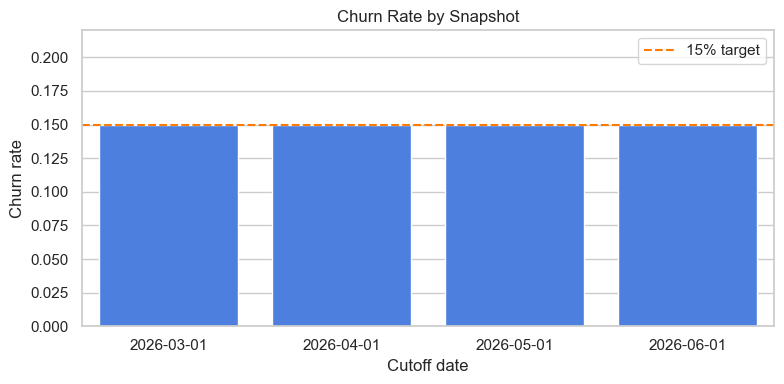

In [15]:
plt.figure(figsize=(8, 4))
plot_data = label_summary.assign(cutoff=label_summary["cutoff_date"].dt.strftime("%Y-%m-%d"))
sns.barplot(data=plot_data, x="cutoff", y="churn_rate", color="#3478F6")
plt.axhline(0.15, color="#FF7A00", linestyle="--", label="15% target")
plt.ylim(0, 0.22)
plt.ylabel("Churn rate")
plt.xlabel("Cutoff date")
plt.title("Churn Rate by Snapshot")
plt.legend()
plt.tight_layout()
plt.show()

## 2. 缺失值查看与处理

### 2.1 为什么检查缺失值？

缺失值可能有完全不同的含义：

- 商家没有客服工单，因此“平均解决时长”无法计算；
- 商家没有评分，因此“平均评分”为空；
- 数据采集失败，真实值未知；
- 分母为 0，导致比率在数学上没有定义。

因此不能先决定“统一填 mean”或“统一填 0”。正确顺序是：

1. 列出所有缺失字段和缺失率；
2. 检查缺失是否来自相同业务条件；
3. 判断缺失本身是否携带预测信号；
4. 再决定填充、保留缺失标记、删除字段或删除记录。

当前 Pipeline **没有使用 mean 填充**。一般数值列使用训练集 median，并增加 missing indicator；类别列填 `Unknown`。后面还会针对结构性缺失做更细的处理。

In [16]:
missingness = pd.DataFrame({
    "feature": model_features,
    "missing_rows": feature_mart[model_features].isna().sum().values,
    "missing_rate": feature_mart[model_features].isna().mean().values,
    "dtype": feature_mart[model_features].dtypes.astype(str).values,
    "unique_values": feature_mart[model_features].nunique(dropna=True).values,
}).sort_values(["missing_rate", "feature"], ascending=[False, True])

# 展示全部 35 个模型输入，而不是只看缺失最多的几列。
missingness.reset_index(drop=True)

,feature,missing_rows,missing_rate,dtype,unique_values
0,promotion_roi_30d,5294,0.662,float64,2400
1,issue_resolution_time_hours,4603,0.575,float64,2542
2,unresolved_ticket_rate_30d,4131,0.516,float64,9
3,order_trend_vs_prev3w,962,0.120,float64,229
4,aov_28d,654,0.082,float64,6891
5,average_rating_28d,654,0.082,float64,469
6,avg_preparation_time_28d,654,0.082,float64,6661
7,cancellation_rate_28d,654,0.082,float64,78
8,days_since_last_order,654,0.082,float64,28
9,late_delivery_rate_28d,654,0.082,float64,158


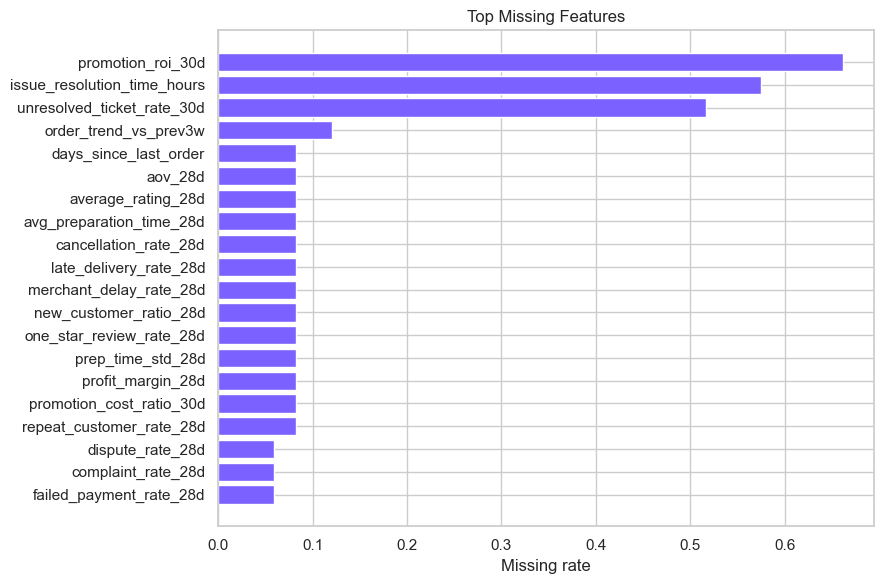

In [17]:
top_missing = missingness.head(20).sort_values("missing_rate")
plt.figure(figsize=(9, 6))
plt.barh(top_missing["feature"], top_missing["missing_rate"], color="#7B61FF")
plt.xlabel("Missing rate")
plt.title("Top Missing Features")
plt.tight_layout()
plt.show()

### 2.2 为什么很多字段的缺失率都是 8.2%？

如果多个字段缺失率完全相同，通常不是巧合，而是它们共享同一个计算条件。

本例中，AOV、评分、备餐时间、复购率、利润率等都需要近期完成订单作为分母或数据来源。当商家在 cutoff 前 28 天没有完成订单时，这些字段会一起缺失。

这叫 **co-missing pattern（共同缺失模式）**。它告诉我们：缺失不是单个字段坏了，而是商家处于“近期无订单”的业务状态。

In [18]:
same_missing_group = [
    "aov_28d",
    "average_rating_28d",
    "avg_preparation_time_28d",
    "days_since_last_order",
    "new_customer_ratio_28d",
    "profit_margin_28d",
    "repeat_customer_rate_28d",
]

co_missing_check = pd.DataFrame({
    "feature": same_missing_group,
    "missing_rows": [feature_mart[c].isna().sum() for c in same_missing_group],
    "missing_rate": [feature_mart[c].isna().mean() for c in same_missing_group],
})
co_missing_check

,feature,missing_rows,missing_rate
0,aov_28d,654,0.082
1,average_rating_28d,654,0.082
2,avg_preparation_time_28d,654,0.082
3,days_since_last_order,654,0.082
4,new_customer_ratio_28d,654,0.082
5,profit_margin_28d,654,0.082
6,repeat_customer_rate_28d,654,0.082


In [19]:
no_recent_completed_order = feature_mart["aov_28d"].isna()

missing_group_profile = pd.DataFrame({
    "group": ["8.2%共同缺失组", "非共同缺失组"],
    "rows": [no_recent_completed_order.sum(), (~no_recent_completed_order).sum()],
    "unique_merchants": [
        feature_mart.loc[no_recent_completed_order, "merchant_id"].nunique(),
        feature_mart.loc[~no_recent_completed_order, "merchant_id"].nunique(),
    ],
    "churn_rate": [
        feature_mart.loc[no_recent_completed_order, "churn_label"].mean(),
        feature_mart.loc[~no_recent_completed_order, "churn_label"].mean(),
    ],
})
missing_group_profile

,group,rows,unique_merchants,churn_rate
0,8.2%共同缺失组,654,350,0.850
1,非共同缺失组,7346,1997,0.088


### 2.3 是否应该删除这 8.2% 的商家？

不应该直接删除。

这 654 条记录的流失率约为 85%，而非缺失组约为 8.8%。如果删除它们，我们实际上是在删除“近期已经没有订单”的高风险商家，会产生严重的选择偏差，并让模型学不到最重要的流失信号。

还要注意：654 是 `merchant × cutoff` 记录数，不等于 654 个永久缺失的商家。同一个商家可能在某个月没有订单、下个月又恢复。因此是否删除必须在正确 grain 下判断。

更合理的处理是：

- 保留这些记录；
- 对无法计算的字段使用合理占位值；
- 增加 missing indicator，让模型知道“这个值原本不存在”；
- 保留订单量、recency 等能直接描述低活跃状态的变量。

### 2.4 本案例的缺失值处理分类

| 分类 | 字段或条件 | 处理方式 | 原因 |
|---|---|---|---|
| Mean | 当前没有推荐字段 | 不使用 | 多数数值偏态明显，而且缺失并非随机；mean 容易受极端值影响 |
| Unknown | `city`、`segment` 等类别字段 | 填 `Unknown` | 缺失类别不应被伪装成已有类别；当前 V3 中这两列没有缺失，但 Pipeline 要能处理未来数据 |
| Median + missing flag | AOV、评分、备餐时间、订单比率、利润率、工单解决时长、订单趋势等 | 使用 Train median，并增加缺失标记 | median 对偏态和极端值更稳健；missing flag 保留“无法计算”这一信息 |
| 业务常量 + missing flag | `days_since_last_order` | 填 29，并增加缺失标记 | SQL 回看 28 天；缺失代表窗口内没有完成订单，29 比 median 更符合业务含义 |
| 结构性 0 + missing flag | `promotion_roi_30d`、`unresolved_ticket_rate_30d` | 填 0，并增加缺失标记 | 没有可计算事件时用 0 作为模型占位，但标记负责区分“真实为 0”和“原本缺失” |
| 考虑删除字段 | 缺失率超过 50% 的字段 | 先做 ablation，再决定 | 高缺失率只是风险提示；字段仍可能携带“没有活动/没有工单”的业务信息 |
| 删除记录 | 主键缺失、标签缺失、无法确定 cutoff、明显坏数据 | 删除或回上游修复 | 这些问题会破坏样本身份或监督学习目标；本数据中没有此类记录 |

Mean 并不是一定错误。对于近似对称、缺失近似随机且业务上适合取平均的连续变量，可以使用 mean。但当前这些缺失大多是结构性缺失，所以没有字段被归入 mean。

In [20]:
high_missing_candidates = missingness.loc[
    missingness["missing_rate"] > 0.50,
    ["feature", "missing_rows", "missing_rate"],
].reset_index(drop=True)
high_missing_candidates

,feature,missing_rows,missing_rate
0,promotion_roi_30d,5294,0.662
1,issue_resolution_time_hours,4603,0.575
2,unresolved_ticket_rate_30d,4131,0.516


### 2.5 缺失率超过 50%，是否一定删除字段？

也不一定。这里超过 50% 的字段主要与促销和客服事件有关：没有促销时 ROI 无法计算，没有已解决工单时解决时长无法计算。

#### 什么是 Ablation Test？

**Ablation test（消融实验）** 是一种“拿掉一部分，再看结果怎么变化”的对照实验。

具体做法是：

1. 先训练包含全部特征的基准模型；
2. 保持数据切分、算法、参数、随机种子和评估指标不变；
3. 只删除一个特征、一组特征或某个模型组件；
4. 重新训练并比较 Validation 表现。

它的核心思想是 **控制变量**。两次实验之间只改变我们想检查的部分，才能把表现变化与这部分联系起来。

例如：

- 完整模型 PR-AUC = 0.78；
- 删除三个高缺失字段后 PR-AUC = 0.80；
- 在其他条件相同的情况下，这组字段没有提供额外预测价值，甚至可能引入噪声。

反过来，如果删除后 PR-AUC 从 0.78 降到 0.70，说明这组字段虽然缺失率高，但仍然包含重要信息，不应该只因为缺失多就删除。

Ablation test 可以回答：

> “模型是否需要这部分信息？”

但它不能直接证明：

> “这个特征在业务上导致了流失。”

它衡量的是模型贡献，不是因果关系。结果还可能受到验证月份、随机波动和相关特征替代效应的影响，因此最好在多个时间窗口重复验证。

删除前至少检查三件事：

1. 线上打分时这个字段能否稳定获得；
2. 缺失本身是否有业务含义；
3. 删除字段后，Validation PR-AUC 和 Top 5% 指标是否明显变化。

缺失率用于提出删除候选，ablation test 提供模型层面的证据，线上可用性和业务含义则提供落地层面的证据。

## 3. 查看单变量分布

### 3.1 数值变量的分布和异常值

对于数值变量，我们至少要看中位数、四分位数、最大值以及偏度。这里使用 IQR 规则标记潜在异常值：低于 `Q1 - 1.5 × IQR` 或高于 `Q3 + 1.5 × IQR`。

IQR 标记只是排查线索，不是自动删除规则。订单量很高的头部商家可能是真实业务对象；如果直接删除，模型就无法服务这部分商家。发现异常值后，应回到原始订单或业务规则确认它是数据错误，还是真实但少见的样本。

In [21]:
numeric_distribution = feature_mart[numeric_features].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]
).T
numeric_distribution["skewness"] = feature_mart[numeric_features].skew()

q1 = feature_mart[numeric_features].quantile(0.25)
q3 = feature_mart[numeric_features].quantile(0.75)
iqr = q3 - q1
outlier_mask = feature_mart[numeric_features].lt(q1 - 1.5 * iqr) | feature_mart[
    numeric_features
].gt(q3 + 1.5 * iqr)
numeric_distribution["iqr_outlier_rate"] = outlier_mask.mean()

numeric_distribution.sort_values("iqr_outlier_rate", ascending=False).head(15)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness,iqr_outlier_rate
cancellation_rate_28d,"7,346.000",0.057,0.179,0.000,0.000,0.000,0.000,0.000,1.000,3.000,7.162,0.223
failed_payment_rate_28d,"7,529.000",0.026,0.073,0.000,0.000,0.000,0.000,0.000,0.282,1.000,6.545,0.202
refund_rate_28d,"7,529.000",0.031,0.071,0.000,0.000,0.000,0.000,0.037,0.286,1.000,4.888,0.128
promotion_cost_ratio_30d,"7,346.000",0.301,1.196,0.000,0.000,0.000,0.000,0.235,4.055,50.655,18.632,0.122
store_open_days_28d,"8,000.000",21.888,6.603,0.000,2.000,22.000,24.000,25.000,28.000,28.000,-2.105,0.115
business_hours_consistency_28d,"8,000.000",0.644,0.204,0.000,0.056,0.627,0.701,0.763,0.869,0.920,-1.863,0.113
unresolved_ticket_rate_30d,"3,869.000",0.170,0.341,0.000,0.000,0.000,0.000,0.000,1.000,1.000,1.752,0.110
temporary_closure_days_28d,"8,000.000",3.374,3.857,0.000,0.000,1.000,2.000,4.000,17.000,22.000,2.112,0.108
menu_ready,"8,000.000",0.903,0.295,0.000,0.000,1.000,1.000,1.000,1.000,1.000,-2.734,0.097
dispute_rate_28d,"7,529.000",0.039,0.090,0.000,0.000,0.000,0.000,0.056,0.333,1.000,5.237,0.087


### 3.2 类别变量的分布

类别变量要检查类别数量、每个类别的样本占比和对应流失率。极少出现的类别可能让 One-hot 特征不稳定；某个类别流失率异常高，也可能说明业务差异、样本过少或数据质量问题。

In [22]:
categorical_eda = pd.concat([
    (
        feature_mart.groupby(feature, dropna=False)
        .agg(rows=("merchant_id", "size"), churn_rate=("churn_label", "mean"))
        .reset_index()
        .rename(columns={feature: "category"})
        .assign(feature=feature)
    )
    for feature in categorical_features
], ignore_index=True)
categorical_eda["row_share"] = categorical_eda["rows"] / len(feature_mart)
categorical_eda[["feature", "category", "rows", "row_share", "churn_rate"]]

,feature,category,rows,row_share,churn_rate
0,city,Berkeley,1368,0.171,0.167
1,city,Fremont,1164,0.145,0.150
2,city,Oakland,1360,0.170,0.149
3,city,Palo Alto,1340,0.168,0.117
4,city,San Francisco,1400,0.175,0.179
5,city,San Jose,1368,0.171,0.136
6,segment,Enterprise,420,0.052,0.062
7,segment,Mid-Market,1720,0.215,0.108
8,segment,SMB,5860,0.733,0.169


## 4. 分析特征与 Y 的关系

我们先比较流失与未流失商家的中位数。这一步不是为了证明因果关系，而是为了：

1. 检查特征方向是否符合业务直觉；
2. 找出可能的数据错误或泄漏；
3. 为模型解释建立预期。

例如，流失商家的近期订单数通常更少，距上次订单天数通常更大。但相关不等于因果，我们不能据此直接说“某变量导致流失”。

In [23]:
eda_features = [
    "weekly_orders_7d",
    "days_since_last_order",
    "order_trend_vs_prev3w",
    "average_rating_28d",
    "complaint_rate_28d",
    "temporary_closure_days_28d",
]

group_medians = feature_mart.groupby("churn_label")[eda_features].median().T
group_medians.columns = ["non_churn_median", "churn_median"]
group_medians["difference"] = (
    group_medians["churn_median"] - group_medians["non_churn_median"]
)
group_medians

,non_churn_median,churn_median,difference
weekly_orders_7d,2.000,0.000,-2.000
days_since_last_order,2.000,3.000,1.000
order_trend_vs_prev3w,-0.040,-0.250,-0.210
average_rating_28d,4.200,4.000,-0.200
complaint_rate_28d,0.000,0.000,0.000
temporary_closure_days_28d,2.000,10.000,8.000


## 5. Feature Engineering：把业务现象转换成模型输入

### 5.1 示例：计算订单变化率

**Feature Engineering（特征工程）** 是把原始数据转换成更能表达业务状态的模型输入。好的特征不只是“增加一列”，而是把业务假设变成一个在预测时点可以计算、并且不会使用未来信息的数字。

例如，只看最近 7 天订单量无法区分两种商家：一家长期每周 10 单、最近仍有 10 单；另一家以前每周 30 单、最近降到 10 单。它们当前订单量相同，但趋势完全不同。

因此我们计算最近一周相对此前三周周均订单量的变化率：

`订单变化率 = (最近 7 天订单数 - 此前 21 天周均订单数) ÷ 此前 21 天周均订单数`

- 大于 0：近期订单增长；
- 等于 0：近期基本稳定；
- 小于 0：近期订单下降，可能是流失预警；
- 此前 21 天为 0：分母为 0，变化率无法定义，保留为缺失并在 Pipeline 中处理。

这个指标已经由 SQL 生成并命名为 `order_trend_vs_prev3w`。下面从订单明细重新计算一次，展示从原始交易到特征的完整过程；它只用于核对公式，不会作为重复变量再次加入模型。

In [24]:
# 1. 为每个 merchant × cutoff 统计最近 7 天和此前 21 天完成订单数。
completed_orders = raw_tables["orders"].loc[
    raw_tables["orders"]["completed_flag"].eq(1),
    ["merchant_id", "order_date"],
].copy()
# CSV 不保存 datetime 类型，因此在进行时间窗口比较前显式转换。
completed_orders["order_date"] = pd.to_datetime(completed_orders["order_date"])

order_change_rows = []
for cutoff in pd.to_datetime(CUTOFF_DATES):
    recent_start = cutoff - pd.Timedelta(days=7)
    history_start = cutoff - pd.Timedelta(days=28)

    recent_counts = (
        completed_orders.loc[
            completed_orders["order_date"].ge(recent_start)
            & completed_orders["order_date"].lt(cutoff)
        ]
        .groupby("merchant_id")
        .size()
    )
    previous_counts = (
        completed_orders.loc[
            completed_orders["order_date"].ge(history_start)
            & completed_orders["order_date"].lt(recent_start)
        ]
        .groupby("merchant_id")
        .size()
    )

    snapshot = feature_mart.loc[
        feature_mart["cutoff_date"].eq(cutoff), ["merchant_id"]
    ].copy()
    snapshot["cutoff_date"] = cutoff
    snapshot["orders_recent_7d"] = snapshot["merchant_id"].map(recent_counts).fillna(0)
    snapshot["orders_previous_21d"] = snapshot["merchant_id"].map(previous_counts).fillna(0)
    snapshot["previous_weekly_average"] = snapshot["orders_previous_21d"] / 3
    snapshot["order_change_rate_calculated"] = (
        snapshot["orders_recent_7d"] - snapshot["previous_weekly_average"]
    ) / snapshot["previous_weekly_average"].replace(0, np.nan)
    order_change_rows.append(snapshot)

order_change_example = pd.concat(order_change_rows, ignore_index=True).merge(
    feature_mart[["merchant_id", "cutoff_date", "order_trend_vs_prev3w"]],
    on=["merchant_id", "cutoff_date"],
    how="left",
)

# 2. 确认 Python 重算结果与 SQL Feature Mart 中的结果一致。
comparable = order_change_example.dropna(
    subset=["order_change_rate_calculated", "order_trend_vs_prev3w"]
)
assert np.allclose(
    comparable["order_change_rate_calculated"],
    comparable["order_trend_vs_prev3w"],
)

order_change_example.head(10)

,merchant_id,cutoff_date,orders_recent_7d,orders_previous_21d,previous_weekly_average,order_change_rate_calculated,order_trend_vs_prev3w
0,M00001,2026-03-01,3.000,3.000,1.000,2.000,2.000
1,M00002,2026-03-01,0.000,5.000,1.667,-1.000,-1.000
2,M00003,2026-03-01,2.000,2.000,0.667,2.000,2.000
3,M00004,2026-03-01,9.000,15.000,5.000,0.800,0.800
4,M00005,2026-03-01,2.000,2.000,0.667,2.000,2.000
5,M00006,2026-03-01,6.000,4.000,1.333,3.500,3.500
6,M00007,2026-03-01,4.000,17.000,5.667,-0.294,-0.294
7,M00008,2026-03-01,2.000,5.000,1.667,0.200,0.200
8,M00009,2026-03-01,4.000,9.000,3.000,0.333,0.333
9,M00010,2026-03-01,5.000,6.000,2.000,1.500,1.500


In [25]:
# 3. 比较流失与未流失商家的订单变化率。
feature_mart.groupby("churn_label")["order_trend_vs_prev3w"].agg(
    rows="count",
    median="median",
    mean="mean",
)

,rows,median,mean
churn_label,,,
0,6583,-0.040,0.189
1,455,-0.250,0.240


### 5.2 类别变量处理

`city` 和 `segment` 是类别名称，不是可以直接计算距离的连续数字。即使把不同类别手工编码成 1、2、3，这些数字的大小关系也没有真实业务含义：模型可能错误地认为类别 3 比类别 1“大两倍”。

本项目使用 **One-hot encoding（独热编码）**：每个类别变成一个独立的 0/1 列。例如 `segment` 会被展开成 `segment_Enterprise`、`segment_Mid-Market` 和 `segment_SMB`。

- 当前记录属于该类别时取 1，否则取 0；
- 类别之间不会被强行加入大小顺序；
- 缺失类别先填为 `Unknown`；
- `handle_unknown="ignore"` 让模型遇到训练时没见过的新类别也能继续预测。

下面先用 Pandas 展示编码前后的变化。正式建模时仍会使用 Pipeline 中的 `OneHotEncoder`，确保编码规则只从 Train 学习。

In [26]:
categorical_example = feature_mart[["city", "segment"]].head(8).copy()
one_hot_example = pd.get_dummies(
    categorical_example,
    columns=["city", "segment"],
    dtype=int,
)

print("编码前：")
display(categorical_example)
print("One-hot 编码后：")
display(one_hot_example)

编码前：


,city,segment
0,Oakland,SMB
1,San Jose,SMB
2,San Francisco,SMB
3,Oakland,Mid-Market
4,San Francisco,SMB
5,Fremont,SMB
6,Oakland,Mid-Market
7,Fremont,SMB


One-hot 编码后：


,city_Fremont,city_Oakland,city_San Francisco,city_San Jose,segment_Mid-Market,segment_SMB
0,0,1,0,0,0,1
1,0,0,0,1,0,1
2,0,0,1,0,0,1
3,0,1,0,0,1,0
4,0,0,1,0,0,1
5,1,0,0,0,0,1
6,0,1,0,0,1,0
7,1,0,0,0,0,1


## 6. 检查时间稳定性和数据泄漏

### 6.1 不同 snapshot 的分布是否稳定？

模型最终会用于未来月份，因此不能只看全量平均值。我们要按 cutoff 比较样本量、流失率以及关键特征的分布：

- 如果流失率突然变化，可能是季节性、业务变化或标签窗口不完整；
- 如果关键特征的中位数大幅漂移，模型在未来月份可能失效；
- 稳定不代表未来一定不会变化，但它能帮助我们发现当前数据中的明显异常。

下面用每个 snapshot 的中位数做一个基础检查。

In [27]:
stability_features = [
    "weekly_orders_7d",
    "gmv_28d",
    "days_since_last_order",
    "average_rating_28d",
]

snapshot_stability = (
    feature_mart.groupby("cutoff_date")
    .agg(
        rows=("merchant_id", "size"),
        merchants=("merchant_id", "nunique"),
        churn_rate=("churn_label", "mean"),
        **{
            f"median_{feature}": (feature, "median")
            for feature in stability_features
        },
    )
    .reset_index()
)
snapshot_stability

,cutoff_date,rows,merchants,churn_rate,median_weekly_orders_7d,median_gmv_28d,median_days_since_last_order,median_average_rating_28d
0,2026-03-01,2000,2000,0.150,2.000,217.310,2.000,4.200
1,2026-04-01,2000,2000,0.150,2.000,208.405,3.000,4.200
2,2026-05-01,2000,2000,0.150,2.000,213.935,3.000,4.200
3,2026-06-01,2000,2000,0.150,2.000,213.905,2.000,4.167


### 6.2 什么是 leakage？

如果预测时间是 `cutoff_date`，模型只能使用当时已经知道的信息。`future_orders_28d` 和 `churn_label` 来自未来 28 天，只能作为标签或验证字段。

一旦把未来信息放进 X，离线分数会异常漂亮，但上线时这些字段根本不存在。下面用集合检查明确阻止这种错误。

In [28]:
leakage_columns = {"future_orders_28d", "churn_label"}
leakage_found = sorted(leakage_columns.intersection(model_features))
print("Leakage columns in X:", leakage_found)
assert not leakage_found

Leakage columns in X: []


### 6.3 切分 Train、Validation 和 Test

#### 为什么不做普通随机行切分？

同一个商家会在四个 snapshot 中重复出现，而且相邻月份的城市、segment、订单量和经营状态通常非常相似。如果随机拆行，同一个商家的 3 月记录可能进入 Train，4 月记录进入 Test。即使模型没有使用 `merchant_id`，它也已经见过这个商家非常相似的历史状态，Train 与 Test 的样本不再真正独立，评估结果可能偏乐观。

#### 比较理想的评估架构：分别检查 Merchant 和时间两个维度

先把商家拆成 80% Development Merchants 和 20% Holdout Merchants，再建立不同用途的数据集：

| 数据集 | 使用的商家 | 使用的 snapshot | 回答的问题 |
|---|---|---|---|
| Train | 80% Development Merchants | 2026-03、2026-04 | 模型从哪些历史样本中学习？ |
| Validation | 80% Development Merchants | 2026-05 | 哪个模型和参数在较新的月份表现更好？ |
| Unseen Merchant Test | 20% Holdout Merchants | 2026-03 至 2026-05 | 模型能否推广到从未参与开发的新商家？ |
| Future Time Test | 80% Development Merchants | 2026-06 | 模型能否推广到更晚的业务月份？ |
| Future Unseen Test（可选） | 20% Holdout Merchants | 2026-06 | 面对未来月份中的新商家时，模型表现如何？ |

#### 本项目采用的简化方案

上面的多测试集设计更完整，但本项目更关注模型对未来时间的预测。为了让课堂主线更清楚，我们使用全部商家，并按照 cutoff date 做严格的时间切分：

- Train：全部商家的 2026-03、2026-04 snapshot；
- Validation：全部商家的 2026-05 snapshot；
- Test：全部商家的 2026-06 snapshot，只用于一次最终评估。

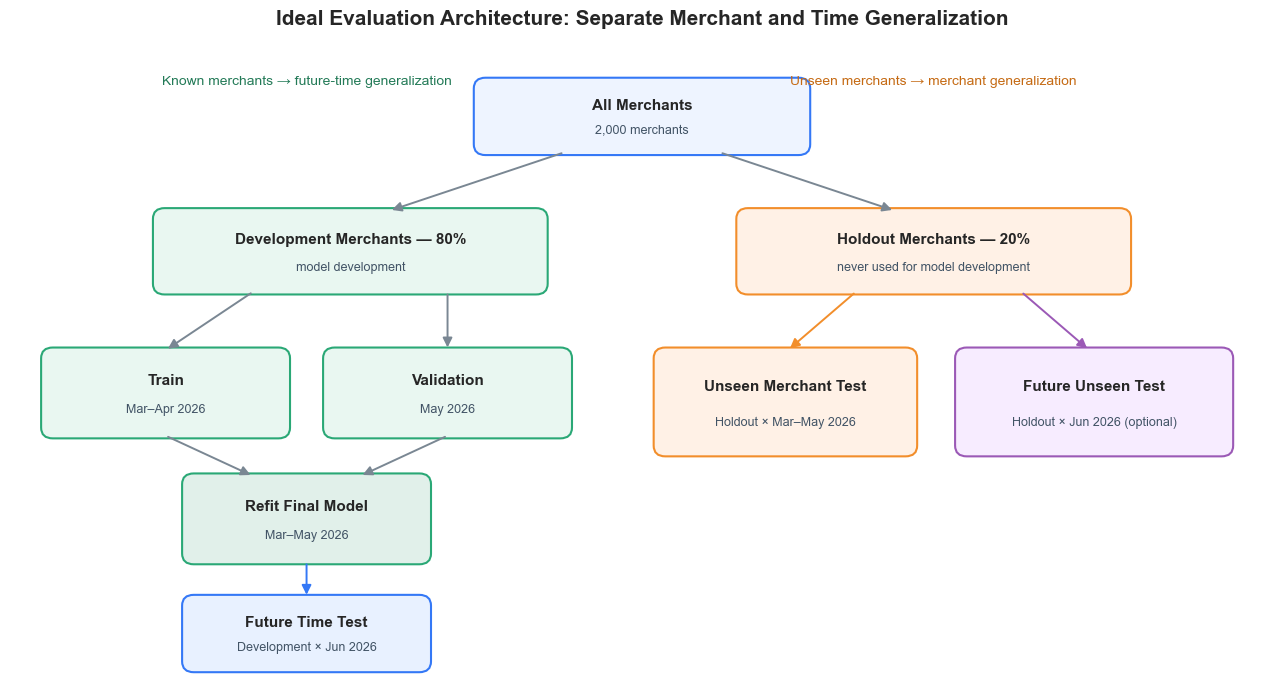

In [29]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 7))
ax.set_xlim(0, 13)
ax.set_ylim(0, 7)
ax.axis("off")

def add_box(x, y, width, height, title, subtitle, facecolor, edgecolor):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.03,rounding_size=0.12",
        linewidth=1.5, edgecolor=edgecolor, facecolor=facecolor,
    )
    ax.add_patch(box)
    ax.text(x + width / 2, y + height * 0.64, title,
            ha="center", va="center", fontsize=11, fontweight="bold")
    ax.text(x + width / 2, y + height * 0.30, subtitle,
            ha="center", va="center", fontsize=9, color="#425466")

def add_arrow(start, end, color="#7A8793"):
    ax.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=14,
        linewidth=1.4, color=color, connectionstyle="arc3,rad=0.0",
    ))

add_box(4.8, 5.8, 3.4, 0.8, "All Merchants", "2,000 merchants", "#EEF4FF", "#3478F6")
add_box(1.5, 4.25, 4.0, 0.9, "Development Merchants — 80%", "model development", "#E9F7F1", "#2AA876")
add_box(7.5, 4.25, 4.0, 0.9, "Holdout Merchants — 20%", "never used for model development", "#FFF1E6", "#F28E2B")
add_arrow((5.7, 5.8), (3.9, 5.15))
add_arrow((7.3, 5.8), (9.1, 5.15))

add_box(0.35, 2.65, 2.5, 0.95, "Train", "Mar–Apr 2026", "#E9F7F1", "#2AA876")
add_box(3.25, 2.65, 2.5, 0.95, "Validation", "May 2026", "#E9F7F1", "#2AA876")
add_box(1.8, 1.25, 2.5, 0.95, "Refit Final Model", "Mar–May 2026", "#E1F0EA", "#2AA876")
add_box(1.8, 0.05, 2.5, 0.8, "Future Time Test", "Development × Jun 2026", "#E8F1FF", "#3478F6")
add_arrow((2.5, 4.25), (1.6, 3.6))
add_arrow((4.5, 4.25), (4.5, 3.6))
add_arrow((1.6, 2.65), (2.5, 2.2))
add_arrow((4.5, 2.65), (3.6, 2.2))
add_arrow((3.05, 1.25), (3.05, 0.85), "#3478F6")

add_box(6.65, 2.45, 2.65, 1.15, "Unseen Merchant Test", "Holdout × Mar–May 2026", "#FFF1E6", "#F28E2B")
add_box(9.75, 2.45, 2.8, 1.15, "Future Unseen Test", "Holdout × Jun 2026 (optional)", "#F7ECFF", "#9B59B6")
add_arrow((8.7, 4.25), (8.0, 3.6), "#F28E2B")
add_arrow((10.4, 4.25), (11.1, 3.6), "#9B59B6")

ax.text(3.05, 6.55, "Known merchants → future-time generalization",
        ha="center", fontsize=10, color="#237A57")
ax.text(9.5, 6.55, "Unseen merchants → merchant generalization",
        ha="center", fontsize=10, color="#C56A13")
ax.set_title("Ideal Evaluation Architecture: Separate Merchant and Time Generalization",
             fontsize=15, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

In [30]:
# 随机种子用于后续模型训练；两个日期决定验证集和测试集。
RANDOM_SEED = 42
VALIDATION_CUTOFF = pd.Timestamp('2026-05-01')
TEST_CUTOFF = pd.Timestamp('2026-06-01')

In [31]:
def split_data(
    feature_mart: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """按照 cutoff date 切分过去、未来验证月份和最终测试月份。"""
    train = feature_mart[
        feature_mart["cutoff_date"] < VALIDATION_CUTOFF
    ].copy()
    validation = feature_mart[
        feature_mart["cutoff_date"] == VALIDATION_CUTOFF
    ].copy()
    test = feature_mart[
        feature_mart["cutoff_date"] == TEST_CUTOFF
    ].copy()

    if validation.empty or test.empty:
        raise ValueError("Validation or test split is empty")
    if not (train["cutoff_date"].max() < validation["cutoff_date"].min() < test["cutoff_date"].min()):
        raise ValueError("Expected Train < Validation < Test in calendar time")
    return train, validation, test

In [32]:
train, validation, test = split_data(feature_mart)

split_summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "merchants": frame["merchant_id"].nunique(),
        "min_cutoff": frame["cutoff_date"].min(),
        "max_cutoff": frame["cutoff_date"].max(),
        "churn_rate": frame["churn_label"].mean(),
    }
    for name, frame in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
])
split_summary

,split,rows,merchants,min_cutoff,max_cutoff,churn_rate
0,train,4000,2000,2026-03-01,2026-04-01,0.150
1,validation,2000,2000,2026-05-01,2026-05-01,0.150
2,test,2000,2000,2026-06-01,2026-06-01,0.150


In [33]:
print("Train max cutoff:", train["cutoff_date"].max().date())
print("Validation cutoff:", validation["cutoff_date"].unique())
print("Test cutoff:", test["cutoff_date"].unique())
print("Train/Test merchant overlap (expected for future scoring):", len(
    set(train["merchant_id"]) & set(test["merchant_id"])
))
assert train["cutoff_date"].max() < validation["cutoff_date"].min()
assert validation["cutoff_date"].max() < test["cutoff_date"].min()

Train max cutoff: 2026-04-01
Validation cutoff: <DatetimeArray>
['2026-05-01 00:00:00']
Length: 1, dtype: datetime64[ns]
Test cutoff: <DatetimeArray>
['2026-06-01 00:00:00']
Length: 1, dtype: datetime64[ns]
Train/Test merchant overlap (expected for future scoring): 2000


### 6.4 建立 leakage-safe 预处理 Pipeline

预处理规则必须只在 Train 上 `fit`：

- 一般数值变量：median imputation，并保留 missing indicator；
- `days_since_last_order`：填业务常量 29，并保留 missing indicator；
- 结构性缺失字段：填 0，并保留 missing indicator；
- Logistic Regression：数值变量额外标准化；
- 类别变量：填 `Unknown` 后 One-hot encoding；
- 新类别：`handle_unknown="ignore"`，避免线上报错；
- Random Forest：不需要标准化，但仍使用相同的缺失值和类别处理逻辑。

#### 为什么 Logistic Regression 需要标准化？

不同数值特征的量纲差异很大：例如订单变化率可能在 -1 到几之间，而 GMV 可能达到数千。如果直接使用原始数值，会带来两个问题：

1. **优化过程更难收敛**：不同特征的数值尺度相差很大，求解器需要在不同方向上使用差异很大的步长；
2. **正则化不公平**：Logistic Regression 通常使用 L1 或 L2 正则化约束系数。相同的系数惩罚作用在不同量纲上，并不代表相同程度的业务影响。

`StandardScaler` 会使用 Train 的均值和标准差，把连续变量转换为大致均值为 0、标准差为 1 的尺度。这样模型训练通常更稳定，正则化对各数值变量也更公平，而且标准化后的系数更便于比较影响方向和相对强弱。

标准化不是因为 Logistic Regression 无法读取原始数值，而是为了改善数值优化和系数解释。Random Forest 根据切分点划分样本，对特征的单位和线性缩放通常不敏感，因此不需要标准化。

把预处理和模型放进同一个 `Pipeline`，可以防止我们不小心先用全量数据计算 median 或类别集合。

In [34]:
# 只有具有明确业务含义的字段使用指定常量，其余数值字段使用 Train median。
BUSINESS_CONSTANT_IMPUTATION = {'days_since_last_order': 29}
STRUCTURAL_ZERO_FEATURES = ['promotion_roi_30d', 'unresolved_ticket_rate_30d']

In [35]:
def make_preprocessor(
    numeric_features: list[str], categorical_features: list[str], scale: bool
) -> ColumnTransformer:
    constant_features = [
        feature
        for feature in BUSINESS_CONSTANT_IMPUTATION
        if feature in numeric_features
    ]
    structural_zero_features = [
        feature for feature in STRUCTURAL_ZERO_FEATURES if feature in numeric_features
    ]
    median_features = [
        feature
        for feature in numeric_features
        if feature not in constant_features
        and feature not in structural_zero_features
    ]

    median_steps = [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ]
    if scale:
        median_steps.append(("scaler", StandardScaler()))
    transformers = [("numeric_median", Pipeline(median_steps), median_features)]

    for feature in constant_features:
        constant_steps = [
            (
                "imputer",
                SimpleImputer(
                    strategy="constant",
                    fill_value=BUSINESS_CONSTANT_IMPUTATION[feature],
                    add_indicator=True,
                ),
            )
        ]
        if scale:
            constant_steps.append(("scaler", StandardScaler()))
        transformers.append(
            (f"business_constant_{feature}", Pipeline(constant_steps), [feature])
        )

    zero_steps = [
        (
            "imputer",
            SimpleImputer(strategy="constant", fill_value=0, add_indicator=True),
        )
    ]
    if scale:
        zero_steps.append(("scaler", StandardScaler()))
    if structural_zero_features:
        transformers.append(
            (
                "structural_zero",
                Pipeline(zero_steps),
                structural_zero_features,
            )
        )

    categorical_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            ),
        ]
    )
    transformers.append(
        ("categorical_unknown", categorical_pipeline, categorical_features)
    )
    return ColumnTransformer(
        transformers,
        remainder="drop",
        verbose_feature_names_out=False,
    )


def build_models(
    numeric_features: list[str], categorical_features: list[str]
) -> dict[str, Pipeline]:
    linear_preprocessor = make_preprocessor(
        numeric_features, categorical_features, scale=True
    )
    tree_preprocessor = make_preprocessor(
        numeric_features, categorical_features, scale=False
    )
    return {
        "dummy_prevalence": Pipeline(
            [
                ("preprocessor", clone(linear_preprocessor)),
                ("model", DummyClassifier(strategy="prior")),
            ]
        ),
        "logistic_unweighted": Pipeline(
            [
                ("preprocessor", clone(linear_preprocessor)),
                (
                    "model",
                    LogisticRegression(max_iter=3000, random_state=RANDOM_SEED),
                ),
            ]
        ),
        "logistic_balanced": Pipeline(
            [
                ("preprocessor", clone(linear_preprocessor)),
                (
                    "model",
                    LogisticRegression(
                        max_iter=3000,
                        class_weight="balanced",
                        random_state=RANDOM_SEED,
                    ),
                ),
            ]
        ),
        "random_forest_balanced": Pipeline(
            [
                ("preprocessor", clone(tree_preprocessor)),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=400,
                        min_samples_leaf=8,
                        max_features="sqrt",
                        class_weight="balanced_subsample",
                        random_state=RANDOM_SEED,
                        n_jobs=-1,
                    ),
                ),
            ]
        ),
    }


def ranking_metrics(
    y_true: pd.Series, probability: np.ndarray, fraction: float
) -> dict[str, float]:
    y_array = np.asarray(y_true)
    k = max(1, int(np.ceil(len(y_array) * fraction)))
    ranked = np.argsort(-probability, kind="stable")
    selected = ranked[:k]
    positives = y_array.sum()
    threshold = float(probability[selected].min())
    return {
        "contacted": int(k),
        "threshold_at_capacity": threshold,
        "precision_at_capacity": float(y_array[selected].mean()),
        "recall_at_capacity": float(
            y_array[selected].sum() / positives if positives else np.nan
        ),
    }


def evaluate_model(
    model_name: str,
    model: Pipeline,
    X: pd.DataFrame,
    y: pd.Series,
    split_name: str,
) -> tuple[dict[str, float | str], np.ndarray]:
    probability = model.predict_proba(X)[:, 1]
    capacity = ranking_metrics(y, probability, OUTREACH_FRACTION)
    row: dict[str, float | str] = {
        "model": model_name,
        "split": split_name,
        "rows": len(y),
        "positive_rate": float(y.mean()),
        "pr_auc": float(average_precision_score(y, probability)),
        "roc_auc": float(roc_auc_score(y, probability)),
        "log_loss": float(log_loss(y, probability, labels=[0, 1])),
        **capacity,
    }
    return row, probability

In [36]:
models = build_models(numeric_features, categorical_features)

# XGBoost 通过一系列浅树逐步修正前一轮的错误，能够学习非线性关系和特征交互。
models["xgboost"] = Pipeline([
    (
        "preprocessor",
        make_preprocessor(numeric_features, categorical_features, scale=False),
    ),
    (
        "model",
        XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            eval_metric="logloss",
            random_state=RANDOM_SEED,
            n_jobs=-1,
        ),
    ),
])
models

{'dummy_prevalence': Pipeline(steps=[('preprocessor',
                  ColumnTransformer(transformers=[('numeric_median',
                                                   Pipeline(steps=[('imputer',
                                                                    SimpleImputer(add_indicator=True,
                                                                                  strategy='median')),
                                                                   ('scaler',
                                                                    StandardScaler())]),
                                                   ['weekly_orders_7d',
                                                    'order_trend_vs_prev3w',
                                                    'gmv_28d', 'aov_28d',
                                                    'unique_customers_28d',
                                                    'new_customer_ratio_28d',
                                                 

In [37]:
imputation_plan = pd.DataFrame([
    {
        "strategy": "business constant + indicator",
        "features": ", ".join(BUSINESS_CONSTANT_IMPUTATION),
    },
    {
        "strategy": "structural zero + indicator",
        "features": ", ".join(STRUCTURAL_ZERO_FEATURES),
    },
    {
        "strategy": "median + indicator",
        "features": "其他存在缺失的数值字段",
    },
    {
        "strategy": "Unknown + one-hot",
        "features": ", ".join(categorical_features),
    },
    {
        "strategy": "mean",
        "features": "当前无推荐字段",
    },
])
imputation_plan

,strategy,features
0,business constant + indicator,days_since_last_order
1,structural zero + indicator,"promotion_roi_30d, unresolved_ticket_rate_30d"
2,median + indicator,其他存在缺失的数值字段
3,Unknown + one-hot,"city, segment"
4,mean,当前无推荐字段


# Part 3｜Train & Evaluate Models

## 从 Baseline 到最终模型选择

这一部分在固定的 Train、Validation 和 Test 口径下训练模型，比较类别不平衡处理方法，并使用与业务目标一致的指标进行评估。模型和参数只能根据 Validation 选择，Test 留到最后使用一次。

## 1. 先建立 Dummy Baseline，再比较模型

Dummy model 不学习特征，只输出训练集的正类比例。它提供最低基准：一个真正有用的模型必须明显超过它。

我们比较：

- `dummy_prevalence`；
- 普通 Logistic Regression；
- `class_weight="balanced"` 的 Logistic Regression；
- balanced Random Forest；
- XGBoost。

XGBoost 是 Gradient Boosted Trees：模型不是一次生成所有树，而是一轮一轮增加新树，让后面的树重点修正前面模型犯下的错误。它通常能学习线性模型难以表达的非线性关系和特征交互。

类别不平衡也不代表必须使用 SMOTE。我们先比较原始比例、class weight 和不同重采样方法，再根据 Validation 的排序指标选择，而不是预先假定某种方法一定最好。

In [38]:
# 假设运营团队每期最多联系风险排名前 5% 的商家。
OUTREACH_FRACTION = 0.05

In [39]:
X_train = train[model_features]
y_train = train["churn_label"].astype(int)
X_validation = validation[model_features]
y_validation = validation["churn_label"].astype(int)

# XGBoost 不必生成或删除样本，也可以通过正类权重处理不平衡。
# 负类数 ÷ 正类数是 scale_pos_weight 的常用起始值。
xgb_class_ratio = (y_train == 0).sum() / (y_train == 1).sum()
models["xgboost_scale_pos_weight"] = Pipeline([
    ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=False)),
    (
        "model",
        XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            scale_pos_weight=xgb_class_ratio,
            eval_metric="logloss",
            random_state=RANDOM_SEED,
            n_jobs=-1,
        ),
    ),
])

fitted_models = {}
validation_rows = []

for model_name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    fitted_models[model_name] = pipeline
    metrics, _ = evaluate_model(
        model_name,
        pipeline,
        X_validation,
        y_validation,
        "validation",
    )
    validation_rows.append(metrics)

validation_metrics = (
    pd.DataFrame(validation_rows)
    .sort_values(["pr_auc", "recall_at_capacity"], ascending=False)
    .reset_index(drop=True)
)
validation_metrics

,model,split,rows,positive_rate,pr_auc,roc_auc,log_loss,contacted,threshold_at_capacity,precision_at_capacity,recall_at_capacity
0,xgboost_scale_pos_weight,validation,2000,0.150,0.839,0.971,0.210,100,0.975,0.890,0.297
1,xgboost,validation,2000,0.150,0.828,0.969,0.155,100,0.898,0.860,0.287
2,random_forest_balanced,validation,2000,0.150,0.814,0.967,0.246,100,0.969,0.850,0.283
3,logistic_unweighted,validation,2000,0.150,0.807,0.971,0.159,100,0.882,0.810,0.270
4,logistic_balanced,validation,2000,0.150,0.794,0.971,0.279,100,0.980,0.810,0.270
5,dummy_prevalence,validation,2000,0.150,0.150,0.500,0.423,100,0.150,0.140,0.047


### 1.1 类别不平衡到底是什么？

当前 Train 中，流失商家约占 15%，未流失商家约占 85%。这叫 **imbalanced data（类别不平衡）**：一个类别的样本明显少于另一个类别。

类别不平衡带来的主要风险不是模型完全不能训练，而是：

- 模型更容易通过预测多数类获得很高的 Accuracy；
- 默认 0.5 阈值可能漏掉大量少数类；
- 少数类对损失函数的影响较小，模型可能不重视流失商家；
- 评估时必须关注 PR-AUC、Recall 和 Precision，而不是只看 Accuracy。

常见处理方法有四类：

| 方法 | 做法 | 优点 | 主要风险 |
|---|---|---|---|
| Class weight | 提高少数类错误的损失权重 | 不改变原始样本 | 权重过大可能牺牲 Precision |
| Random oversampling | 重复抽取少数类样本，直到类别更平衡 | 不丢多数类数据 | 重复过多可能过拟合 |
| Random undersampling | 随机删除一部分多数类样本 | 训练更快 | 可能删除重要多数类模式 |
| SMOTE | 在相近少数类样本之间合成新样本 | 不只是简单复制 | 可能生成不合理样本，且对类别变量要谨慎 |

没有一种方法永远最好。我们会固定 Train/Validation 和模型主体，通过验证指标做对照实验。

In [40]:
train_class_distribution = (
    y_train.value_counts()
    .rename_axis("churn_label")
    .rename("rows")
    .to_frame()
)
train_class_distribution["share"] = train_class_distribution["rows"] / len(y_train)
train_class_distribution

,rows,share
churn_label,,
0,3400,0.850
1,600,0.150


### 1.2 Oversampling、Undersampling 与 SMOTE

重采样只能发生在 Train 内部。Validation 和 Test 必须保留真实类别比例，否则评估结果无法代表真实业务环境。

正确顺序是：

`先切分数据 → 只在 Train fold 内学习预处理 → 只对 Train 重采样 → 训练模型 → 在原始 Validation/Test 上评估`

如果在切分之前做 SMOTE，某个合成样本可能同时利用未来 Validation/Test 中的信息，形成数据泄漏。把 sampler 放进 `imblearn.Pipeline`，可以确保交叉验证或训练时只处理当前 training fold。

In [41]:
# 先用训练集拟合预处理器，只为了展示不同 sampler 会产生多少样本。
sampling_preprocessor = make_preprocessor(
    numeric_features,
    categorical_features,
    scale=True,
)
X_train_processed = sampling_preprocessor.fit_transform(X_train, y_train)

samplers = {
    "original": None,
    "random_oversampling": RandomOverSampler(random_state=RANDOM_SEED),
    "random_undersampling": RandomUnderSampler(random_state=RANDOM_SEED),
    # SMOTE（Synthetic Minority Over-sampling Technique）不是复制少数类：
    # 1. 为一个少数类样本寻找附近的少数类邻居；
    # 2. 在两点之间随机插值；
    # 3. 用插值得到的新点作为“合成少数类样本”。
    # 这样能让少数类边界更连续，但新点不一定对应真实存在的商家。
    # 本例在 One-hot 后的数值空间中演示；生产项目若有较多类别字段，
    # 应优先评估 SMOTENC，避免产生难以解释的分数类别。
    "smote": SMOTE(random_state=RANDOM_SEED, k_neighbors=5),
}

sampling_counts = []
for sampler_name, sampler in samplers.items():
    if sampler is None:
        sampled_y = y_train.to_numpy()
    else:
        _, sampled_y = sampler.fit_resample(X_train_processed, y_train)
    counts = pd.Series(sampled_y).value_counts()
    sampling_counts.append({
        "method": sampler_name,
        "non_churn_rows": int(counts.get(0, 0)),
        "churn_rows": int(counts.get(1, 0)),
        "total_rows": len(sampled_y),
        "churn_share": float(np.mean(sampled_y)),
    })

pd.DataFrame(sampling_counts)

,method,non_churn_rows,churn_rows,total_rows,churn_share
0,original,3400,600,4000,0.150
1,random_oversampling,3400,3400,6800,0.500
2,random_undersampling,600,600,1200,0.500
3,smote,3400,3400,6800,0.500


### 1.3 在同一个 Logistic Regression 上公平比较不平衡处理方法

为了只比较“不平衡处理方法”的影响，下面保持 Logistic Regression、预处理、Train/Validation 和随机种子一致，只改变 class weight 或 sampler。

另外加入 `XGBoost + scale_pos_weight`：它不生成或删除样本，而是在 XGBoost 的损失函数中提高流失类的权重。常用起点是：

`scale_pos_weight = 负类样本数 ÷ 正类样本数`

In [42]:
def logistic_after_sampling():
    return LogisticRegression(max_iter=3000, random_state=RANDOM_SEED)


imbalance_models = {
    "logistic_original_ratio": Pipeline([
        ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=True)),
        ("model", logistic_after_sampling()),
    ]),
    "logistic_class_weight": Pipeline([
        ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=True)),
        (
            "model",
            LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                random_state=RANDOM_SEED,
            ),
        ),
    ]),
    "logistic_random_oversampling": ImbalancedPipeline([
        ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=True)),
        ("sampler", RandomOverSampler(random_state=RANDOM_SEED)),
        ("model", logistic_after_sampling()),
    ]),
    "logistic_random_undersampling": ImbalancedPipeline([
        ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=True)),
        ("sampler", RandomUnderSampler(random_state=RANDOM_SEED)),
        ("model", logistic_after_sampling()),
    ]),
    "logistic_smote": ImbalancedPipeline([
        ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=True)),
        # sampler 位于 Pipeline 内部，因此只会 fit_resample 训练数据；
        # predict 时 Validation/Test 只做 transform，不会被 SMOTE 改写。
        ("sampler", SMOTE(random_state=RANDOM_SEED, k_neighbors=5)),
        ("model", logistic_after_sampling()),
    ]),
}

negative_positive_ratio = (y_train == 0).sum() / (y_train == 1).sum()
imbalance_models["xgboost_scale_pos_weight"] = Pipeline([
    ("preprocessor", make_preprocessor(numeric_features, categorical_features, scale=False)),
    (
        "model",
        XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.85,
            colsample_bytree=0.85,
            scale_pos_weight=negative_positive_ratio,
            eval_metric="logloss",
            random_state=RANDOM_SEED,
            n_jobs=-1,
        ),
    ),
])

imbalance_rows = []
fitted_imbalance_models = {}
for method_name, pipeline in imbalance_models.items():
    pipeline.fit(X_train, y_train)
    fitted_imbalance_models[method_name] = pipeline
    metrics, _ = evaluate_model(
        method_name,
        pipeline,
        X_validation,
        y_validation,
        "validation",
    )
    imbalance_rows.append(metrics)

imbalance_comparison = (
    pd.DataFrame(imbalance_rows)
    .sort_values(["pr_auc", "recall_at_capacity"], ascending=False)
    .reset_index(drop=True)
)
imbalance_comparison[
    [
        "model",
        "pr_auc",
        "roc_auc",
        "precision_at_capacity",
        "recall_at_capacity",
    ]
]

,model,pr_auc,roc_auc,precision_at_capacity,recall_at_capacity
0,xgboost_scale_pos_weight,0.839,0.971,0.890,0.297
1,logistic_original_ratio,0.807,0.971,0.810,0.270
2,logistic_class_weight,0.794,0.971,0.810,0.270
3,logistic_random_oversampling,0.787,0.970,0.810,0.270
4,logistic_smote,0.784,0.969,0.800,0.267
5,logistic_random_undersampling,0.758,0.968,0.770,0.257


### 如何选择不平衡处理方法？

选择时不要只找 Recall 最高的方法。Random undersampling 或过大的 class weight 可能提高 Recall，却让误报增加、概率校准变差。

本项目的优先级是：

1. 先比较 Validation PR-AUC；
2. 再看运营容量下的 Precision@Top 5% 和 Recall@Top 5%；
3. 如果多个方法相近，优先选择更简单、更稳定、更容易解释的方法。

SMOTE 是一个候选工具，不是类别不平衡的默认答案。

在当前 Validation 中可以看到：

- `xgboost_scale_pos_weight` 的 PR-AUC 和 Top 5% 覆盖表现最好；
- Random undersampling 在 Logistic Regression 方案中表现较强，但它确实丢弃了大量未流失样本；
- Random oversampling 和 SMOTE 没有超过原始比例 Logistic；

因此本案例不会因为 SMOTE 更复杂就优先选择它，而是让验证结果和业务目标决定方案。

### 1.4 用 ablation test 检查高缺失字段是否值得保留

我们固定 Random Forest 和相同的 Train/Validation，只删除缺失率超过 50% 的字段，再比较验证指标。这样才能区分“缺失率很高”和“对模型没有价值”这两个不同问题。

这只是删除字段的一个证据，还要结合线上可用性、稳定性和解释成本一起判断。

In [43]:
drop_candidates = high_missing_candidates["feature"].tolist()
reduced_features = [c for c in model_features if c not in drop_candidates]
reduced_numeric = [c for c in numeric_features if c in reduced_features]
reduced_categorical = [c for c in categorical_features if c in reduced_features]

reduced_forest = build_models(
    reduced_numeric,
    reduced_categorical,
)["random_forest_balanced"]
reduced_forest.fit(train[reduced_features], y_train)
reduced_metrics, _ = evaluate_model(
    "random_forest_drop_high_missing",
    reduced_forest,
    validation[reduced_features],
    y_validation,
    "validation",
)

full_forest_metrics = validation_metrics.loc[
    validation_metrics["model"].eq("random_forest_balanced")
].iloc[0].to_dict()

ablation_comparison = pd.DataFrame([
    full_forest_metrics,
    reduced_metrics,
])[
    [
        "model",
        "pr_auc",
        "roc_auc",
        "precision_at_capacity",
        "recall_at_capacity",
    ]
]
ablation_comparison

,model,pr_auc,roc_auc,precision_at_capacity,recall_at_capacity
0,random_forest_balanced,0.814,0.967,0.850,0.283
1,random_forest_drop_high_missing,0.816,0.967,0.850,0.283


### 1.5 如何解读这次 ablation 结果？

在当前固定 Validation 中，删除三个高缺失字段后：

- PR-AUC 从约 0.777 提升到 0.797；
- Precision@Top 5% 从 82.5% 提升到 85%；
- Recall@Top 5% 也略有提升。

这说明 `promotion_roi_30d`、`issue_resolution_time_hours` 和 `unresolved_ticket_rate_30d` 在当前版本中没有带来额外价值，反而可能增加噪声，因此可以列为下一版模型的删除候选。

但我们仍不应只凭一个验证月份做永久决定。更稳妥的结论是：

1. 不删除缺失的商家记录；
2. 把这三个字段标记为删除候选；
3. 在多个未来月份重复 ablation；
4. 如果表现持续不下降，而且线上采集成本较高，再从正式特征中删除。

这里区分了两个常被混淆的问题：**删除行会改变目标人群，删除字段只会改变模型输入。**

## 2. 为什么主要看 PR-AUC 和 Top 5% 指标？

- **PR-AUC**：关注正类的 Precision–Recall 权衡，适合流失商家少于未流失商家的场景；
- **Recall@Top 5%**：运营只能联系 5% 商家时，能覆盖多少真实流失商家；
- **Precision@Top 5%**：被联系商家中，有多少确实会流失；
- **ROC-AUC**：保留作为整体排序能力的补充；
- **Log loss**：衡量预测概率的质量；模型对错误结果越自信，受到的惩罚越大。

这里的阈值不是固定 0.5，而是由运营容量决定：把风险最高的 5% 商家交给运营团队。

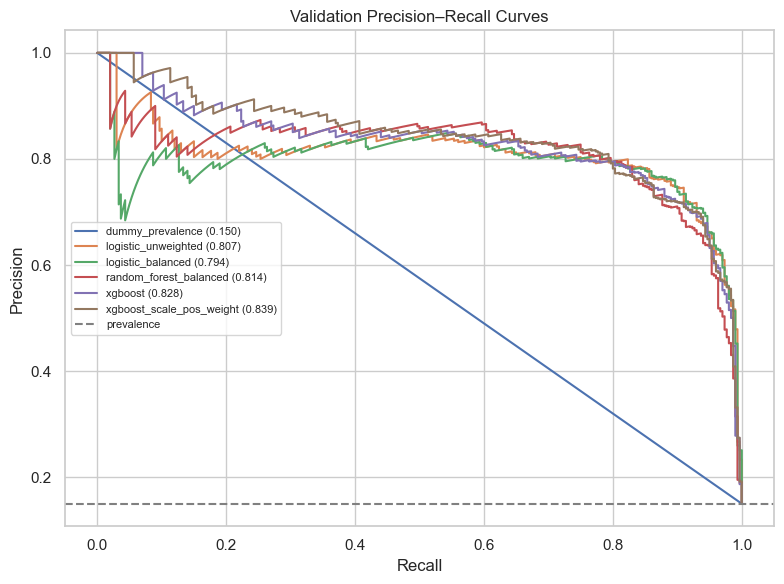

In [44]:
plt.figure(figsize=(8, 6))
for model_name, pipeline in fitted_models.items():
    probability = pipeline.predict_proba(X_validation)[:, 1]
    precision, recall, _ = precision_recall_curve(y_validation, probability)
    pr_auc = average_precision_score(y_validation, probability)
    plt.plot(recall, precision, label=f"{model_name} ({pr_auc:.3f})")

plt.axhline(y_validation.mean(), color="gray", linestyle="--", label="prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision–Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. 只用 Validation 选择模型，然后进行一次最终测试

<div style="display:grid; grid-template-columns:repeat(5, 1fr); gap:10px; margin:18px 0 26px 0;">
  <div style="border:1px solid #9bbcff; border-top:5px solid #3478f6; padding:14px;"><strong>3.1 数据职责</strong><br><span style="color:#53627a;">区分 Train、Validation 与 Test</span></div>
  <div style="border:1px solid #9bbcff; border-top:5px solid #3478f6; padding:14px;"><strong>3.2 普通 Validation</strong><br><span style="color:#53627a;">一次性留出验证集</span></div>
  <div style="border:1px solid #8dd8c5; border-top:5px solid #18a582; padding:14px;"><strong>3.3 K-fold</strong><br><span style="color:#53627a;">轮流训练与验证</span></div>
  <div style="border:1px solid #f4bf8d; border-top:5px solid #ff8b2c; padding:14px;"><strong>3.4 时间切分</strong><br><span style="color:#53627a;">3–4 月训练，5 月验证</span></div>
  <div style="border:1px solid #c1aef2; border-top:5px solid #7b61ff; padding:14px;"><strong>3.5 最终测试</strong><br><span style="color:#53627a;">合并开发数据，Test 一次</span></div>
</div>

### 3.1 Train、Validation 和 Test 分别做什么？

三组数据必须包含不同的数据行，并承担不同职责：

| 数据集 | 模型开发中的作用 | 是否参与当前模型的 `fit`？ |
|---|---|---|
| **Train** | 学习缺失值填补、标准化、One-hot 规则和模型参数 | 是 |
| **Validation** | 比较模型、特征、不平衡处理方法、超参数和阈值 | 否，只用于模型选择 |
| **Test** | 在所有选择结束后，评估模型面对未参与开发数据时的表现 | 否，只做一次最终评估 |

这里的“不一样”指三组数据行不重叠。它们可以来自同一套业务系统，Train 和 Validation 甚至可以包含相同商家在不同月份的 snapshot，但不能是同一条 `merchant_id × cutoff_date` 记录。

为什么不能使用 Train 的分数选择模型？因为模型已经学习过这些数据。复杂模型可能只是把 Train 拟合得更好，却无法泛化到未见数据。因此，训练模型之后还需要用没有参与 `fit` 的数据进行验证。

### 3.2 方法一：普通 Validation（Holdout Validation）

最直接的方法是先保留 Test，再从开发数据中一次性拆出 Train 和 Validation：

`全部数据 → Train + Validation + Test`

模型只在 Train 上训练，再到 Validation 上比较表现。这种方法简单、计算成本低，而且 Validation 的业务含义清楚；但结果可能受到这一次样本划分的影响。如果数据量较小，恰好分到哪些样本可能明显改变结果。

常见的随机分类任务可以使用 `train_test_split(..., stratify=y)`，让 Train 和 Validation 保持相近的 Y 分布。如果同一个用户或商家有多条记录，还需要按 entity 分组，避免同一个对象同时进入两边。

### 3.3 方法二：K-fold Cross-validation

K-fold 不单独固定一份 Validation，而是在开发数据内部轮流验证：

1. 把开发数据分成 K 份；
2. 每次使用 K−1 份训练，剩余 1 份作为 Validation；
3. 重复 K 次，让每一份都做过一次 Validation；
4. 汇总 K 次指标的平均值和波动，再选择模型或参数。

K-fold 能减少一次随机划分带来的偶然性，也能更充分利用有限的开发数据，但训练成本约增加到 K 倍。对于重复商家数据，应考虑 `GroupKFold` 或 `StratifiedGroupKFold`，而不是直接随机拆行。

无论使用普通 Validation 还是 K-fold，缺失值填补、标准化、One-hot 和重采样都必须只在当前 training split 或 training fold 内 `fit`。Test 始终独立保留。Appendix A 会进一步比较不同 cross-validation 方法。

下面用 5-fold 示意图展示轮换过程。每一行代表一次完整训练：蓝色的 4 份用于 Train，橙色的 1 份用于 Validation。五轮结束后，每一份数据都恰好做过一次 Validation。

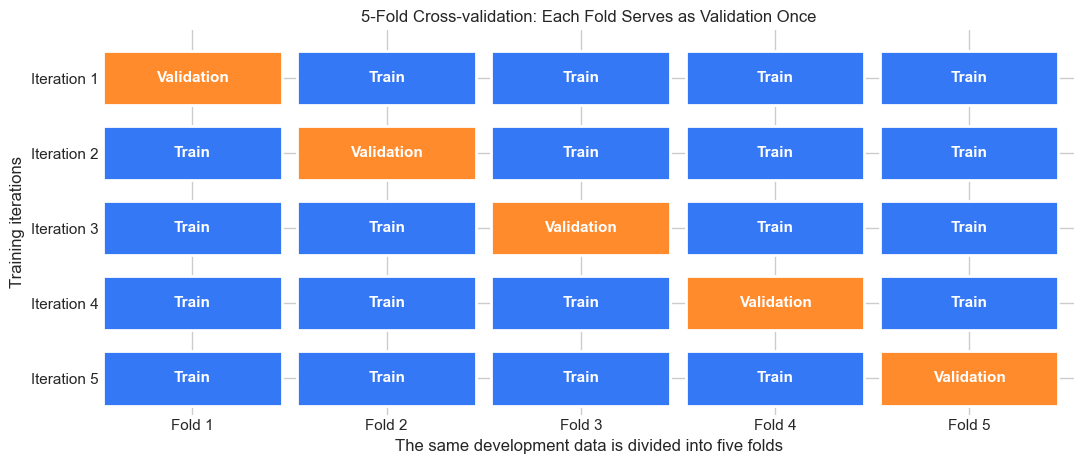

In [45]:
K = 5
fig, ax = plt.subplots(figsize=(11, 4.8))

for iteration in range(K):
    for fold in range(K):
        is_validation = fold == iteration
        color = "#FF8B2C" if is_validation else "#3478F6"
        label = "Validation" if is_validation else "Train"
        rectangle = plt.Rectangle(
            (fold, K - 1 - iteration),
            0.92,
            0.72,
            facecolor=color,
            edgecolor="white",
            linewidth=2,
        )
        ax.add_patch(rectangle)
        ax.text(
            fold + 0.46,
            K - 1 - iteration + 0.36,
            label,
            ha="center",
            va="center",
            color="white",
            fontsize=11,
            fontweight="bold",
        )

ax.set_xlim(0, K)
ax.set_ylim(-0.12, K)
ax.set_xticks(np.arange(K) + 0.46)
ax.set_xticklabels([f"Fold {i}" for i in range(1, K + 1)])
ax.set_yticks(np.arange(K) + 0.36)
ax.set_yticklabels([f"Iteration {i}" for i in range(K, 0, -1)])
ax.set_xlabel("The same development data is divided into five folds")
ax.set_ylabel("Training iterations")
ax.set_title("5-Fold Cross-validation: Each Fold Serves as Validation Once")
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

图中没有 Test：Test 不参与这五轮训练、验证或模型选择，仍然留到最后只使用一次。

### 3.4 为什么本案例使用 3、4 月训练，5 月验证？

本项目最终要用历史行为预测未来月份的商家流失，因此选择按时间进行 Holdout Validation：

- **Train**：development merchants 的 2026-03 和 2026-04 snapshots；
- **Validation**：同一批 development merchants 的 2026-05 snapshot；
- **Test**：预先保留的 20% merchants 的 2026-06 snapshot。

站在 4 月底，我们只能用已经成熟的 3、4 月样本训练，再用 5 月模拟“下一个尚未见过的月份”。这更接近真实开发流程：用过去训练，在未来验证。

如果把 3、4、5 月混合后随机抽一部分做 Train、剩余部分做 Validation，模型虽然没有见过 Validation 的那些具体数据行，却已经通过 Train 中其他 5 月记录接触过 5 月的整体环境，例如当月的订单水平、促销活动和季节性。这样的验证更接近“同一月份内预测其他样本”，而不是“用历史预测未来月份”。

因此，两种切分都不是绝对错误，它们回答的问题不同：

- 混合随机切分：模型对同一时间范围内未见样本的表现如何？
- 按时间切分：模型进入未来月份后还能否保持表现？

本案例更关心第二个问题，所以使用 3、4 月 Train 和 5 月 Validation。

### 3.5 本案例如何完成模型选择和最终测试？

对每一个候选方案，我们只在 Train 上 `fit`，再对 Validation 执行 `transform` 和 `predict_proba`，并比较 PR-AUC、ROC-AUC、Log loss、Precision@Top 5% 和 Recall@Top 5%。模型、类别不平衡方法和参数都只能根据 Validation 选择。

模型选择完成后，将 Train 与 Validation 合并，重新训练获胜模型，使最终模型能够使用截至 5 月的全部开发数据。然后在 Test 上评估一次。

如果反复查看 Test 并据此修改模型，Test 就会变成另一个 Validation，最终指标也会偏乐观。

In [46]:
winner_name = validation_metrics.loc[0, "model"]
development = pd.concat([train, validation], ignore_index=True)
winner = clone(models[winner_name])
winner.fit(
    development[model_features],
    development["churn_label"].astype(int),
)

test_metrics, test_probability = evaluate_model(
    winner_name,
    winner,
    test[model_features],
    test["churn_label"].astype(int),
    "test",
)

print("Selected model:", winner_name)
pd.DataFrame([test_metrics])

Selected model: xgboost_scale_pos_weight


,model,split,rows,positive_rate,pr_auc,roc_auc,log_loss,contacted,threshold_at_capacity,precision_at_capacity,recall_at_capacity
0,xgboost_scale_pos_weight,test,2000,0.150,0.843,0.977,0.168,100,0.969,0.890,0.297


# Part 4｜Turn Predictions into Actions

## 从预测概率到业务决策与模型解释

模型输出的概率本身还不是行动方案。我们需要根据运营容量选择联系阈值、生成商家名单，并解释哪些特征推动了风险预测，以及这些解释可以支持什么业务讨论。

## 1. 把模型分数转换为运营名单

运营容量为 5%，所以我们选择 Test 中风险最高的 5% 商家。`threshold_at_capacity` 是第 5% 名商家的风险分数，而不是人为规定的 0.5。

这样定义阈值有两个好处：

1. 名单大小始终符合团队容量；
2. 可以直接解释 Precision 和 Recall 的业务含义。

In [47]:
threshold = test_metrics["threshold_at_capacity"]
scored_test = test[["merchant_id", "cutoff_date", "churn_label"]].copy()
scored_test["risk_score"] = test_probability
scored_test = scored_test.sort_values("risk_score", ascending=False)
scored_test["selected_for_outreach"] = scored_test["risk_score"] >= threshold

outreach_list = scored_test[scored_test["selected_for_outreach"]]
print("Outreach capacity:", f"{OUTREACH_FRACTION:.0%}")
print("Merchants selected:", len(outreach_list))
outreach_list.head(10)

Outreach capacity: 5%
Merchants selected: 100


,merchant_id,cutoff_date,churn_label,risk_score,selected_for_outreach
6373,M00374,2026-06-01,1,0.994,True
7821,M01822,2026-06-01,1,0.990,True
7372,M01373,2026-06-01,1,0.990,True
7560,M01561,2026-06-01,1,0.988,True
6331,M00332,2026-06-01,1,0.988,True
7569,M01570,2026-06-01,1,0.987,True
7643,M01644,2026-06-01,1,0.987,True
7994,M01995,2026-06-01,1,0.987,True
7497,M01498,2026-06-01,1,0.986,True
7485,M01486,2026-06-01,1,0.986,True


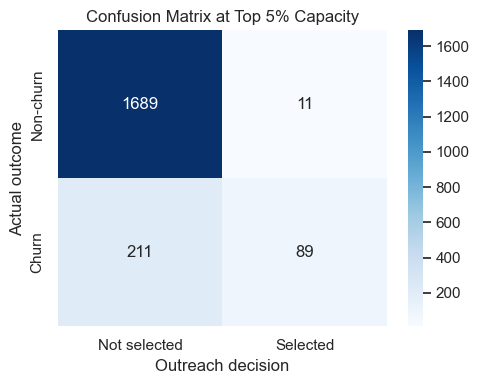

In [48]:
prediction = scored_test["selected_for_outreach"].astype(int)
matrix = confusion_matrix(scored_test["churn_label"], prediction)

plt.figure(figsize=(5, 4))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not selected", "Selected"],
    yticklabels=["Non-churn", "Churn"],
)
plt.xlabel("Outreach decision")
plt.ylabel("Actual outcome")
plt.title("Confusion Matrix at Top 5% Capacity")
plt.tight_layout()
plt.show()

## 2. 开始解释前：我们有哪些模型解释方法？

不同方法回答的问题并不相同。看到一张 Importance 排名表时，先判断它衡量的是系数、切分收益、测试表现下降，还是单条预测的贡献。

| 方法 | 回答的问题 | 能否看方向 | 主要局限 |
|---|---|---|---|
| Logistic coefficient | 控制其他变量后，变量如何影响 log-odds | 有正负 | 对标准化和共线性非常敏感 |
| Random Forest impurity importance | 训练树时，特征贡献了多少切分收益（使用该指标切分后，同一节点中的样本是否更属于同一类别、纯度是否更高） | 不能 | 偏向可切分点较多的变量，而且基于训练过程 |
| Permutation Importance | 打乱一个特征后，测试指标下降多少 | 不能 | 相关特征可以互相替代，单个变量的重要性可能被低估 |
| Mean absolute SHAP | 特征对预测的平均影响强度 | 汇总后不能 | 只看绝对值会失去方向 |
| SHAP Beeswarm / Scatter | 特征对每个样本是推高还是降低预测 | 可以 | 解释的是模型行为，不代表因果关系 |

本项目会依次查看 Logistic coefficient、Permutation Importance 和 SHAP。Random Forest 自带的 `feature_importances_` 只能表示重要程度，不能告诉我们特征取值升高后风险是上升还是下降。

## 3. 模型解释一：Logistic Regression 系数

对于经过标准化的数值变量：

- 系数为正：变量增大与更高流失风险相关；
- 系数为负：变量增大与更低流失风险相关；
- `exp(coefficient)` 是 odds ratio。

系数解释的是“控制其他变量后模型如何使用这个变量”，仍然不是因果结论。One-hot 类别系数还需要相对于被省略或对应的参考状态理解。数值特征经过标准化后，odds ratio 表示特征增加一个标准差时的条件变化，而不是原始单位增加 1。

In [49]:
logistic = fitted_models["logistic_balanced"]
encoded_names = logistic.named_steps["preprocessor"].get_feature_names_out()
coefficients = logistic.named_steps["model"].coef_[0]

coefficient_table = pd.DataFrame({
    "feature": encoded_names,
    "coefficient": coefficients,
    "odds_ratio": np.exp(coefficients),
    "absolute_coefficient": np.abs(coefficients),
}).sort_values("absolute_coefficient", ascending=False)

coefficient_table.head(15)

,feature,coefficient,odds_ratio,absolute_coefficient
62,segment_SMB,-3.352,0.035,3.352
9,business_hours_consistency_28d,-3.176,0.042,3.176
60,segment_Enterprise,3.080,21.749,3.080
4,unique_customers_28d,-3.034,0.048,3.034
8,store_open_days_28d,2.907,18.309,2.907
21,commission_paid_28d,-1.863,0.155,1.863
2,gmv_28d,-0.849,0.428,0.849
7,promotion_participation_30d,-0.385,0.681,0.385
52,missingindicator_promotion_roi_30d,-0.303,0.739,0.303
46,missingindicator_issue_resolution_time_hours,0.300,1.350,0.300


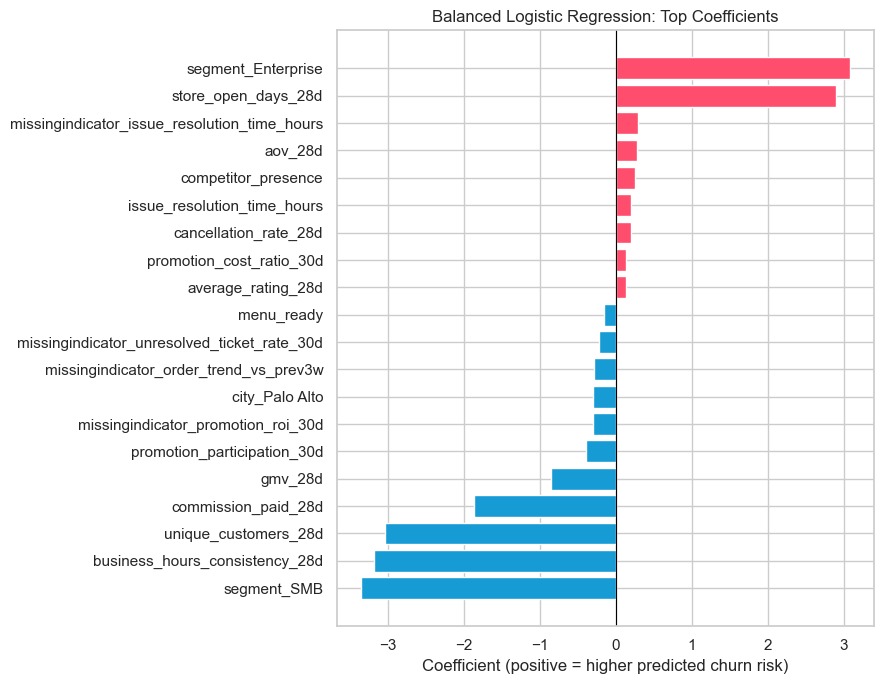

In [50]:
top_coefficients = coefficient_table.head(20).sort_values("coefficient")
colors = np.where(top_coefficients["coefficient"] >= 0, "#FF4D6D", "#169BD5")

plt.figure(figsize=(9, 7))
plt.barh(top_coefficients["feature"], top_coefficients["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (positive = higher predicted churn risk)")
plt.title("Balanced Logistic Regression: Top Coefficients")
plt.tight_layout()
plt.show()

### 3.1 为什么 `store_open_days_28d` 的系数是正数？

从原始数据看，流失商家的平均开店天数明显更少，所以不能把正系数直接翻译成“开店越多越容易流失”。Logistic Regression 的系数表示：**控制模型中的其他变量后**，该变量增加所产生的条件影响。

这里的 `store_open_days_28d`、`business_hours_consistency_28d` 和 `temporary_closure_days_28d` 都在描述营业稳定性。当多个特征高度重叠时，Logistic Regression 很难稳定地把影响分配给某一个变量，可能出现系数变大、方向反转，或者换一批样本后符号改变。

常用的共线性诊断包括：

- **Correlation coefficient**：先检查两两线性相关性；绝对值接近 1 表示高度相关；
- **VIF（Variance Inflation Factor）**：衡量一个变量能被其他变量解释到什么程度；常见经验线是 `VIF > 5` 需要关注，`VIF > 10` 表示严重共线性；
- **Tolerance**：`Tolerance = 1 / VIF`；越接近 0，共线性越严重；
- **Condition Number**：从整个特征矩阵判断数值不稳定性；它会受变量尺度影响，因此通常先标准化再计算。

这些阈值只是诊断提示，不是机械删除变量的规则。还要结合特征含义、模型目标和跨样本稳定性判断。

In [51]:
from sklearn.linear_model import LinearRegression

operating_features = [
    "store_open_days_28d",
    "business_hours_consistency_28d",
    "temporary_closure_days_28d",
]
diagnostic_data = train[operating_features].dropna().copy()

# 1. 两两相关系数：先检查这些变量是否在重复描述相同的业务状态。
display(diagnostic_data.corr().round(3))

# 2. VIF 与 Tolerance：依次用其他变量预测当前变量。
vif_rows = []
for feature in operating_features:
    other_features = [name for name in operating_features if name != feature]
    r_squared = LinearRegression().fit(
        diagnostic_data[other_features], diagnostic_data[feature]
    ).score(diagnostic_data[other_features], diagnostic_data[feature])
    tolerance = 1 - r_squared
    vif_rows.append({
        "feature": feature,
        "R_squared_from_other_features": r_squared,
        "tolerance": tolerance,
        "VIF": 1 / tolerance,
    })

vif_table = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)
display(vif_table.round(3))

# 3. Condition Number：先标准化，避免仅由单位不同造成数值放大。
standardized_operating_features = StandardScaler().fit_transform(diagnostic_data)
condition_number = np.linalg.cond(standardized_operating_features)
print("Standardized condition number:", round(condition_number, 2))

,store_open_days_28d,business_hours_consistency_28d,temporary_closure_days_28d
store_open_days_28d,1.000,0.979,-0.933
business_hours_consistency_28d,0.979,1.000,-0.912
temporary_closure_days_28d,-0.933,-0.912,1.000


,feature,R_squared_from_other_features,tolerance,VIF
0,store_open_days_28d,0.968,0.032,31.277
1,business_hours_consistency_28d,0.959,0.041,24.110
2,temporary_closure_days_28d,0.871,0.129,7.728


Standardized condition number: 12.31


### 3.2 本项目如何使用 Logistic coefficient？

Logistic coefficient 确实带有方向，但**有方向不等于可以直接解释**。本项目存在高度共线的经营稳定性和交易规模变量，因此不把 Logistic coefficient 作为主要的业务解释工具，也不把 `store_open_days_28d` 的正系数解释成“开店越多越容易流失”。

实践中，我们一般不会单独依赖 Logistic coefficient 解释这种高度共线的数据。这里保留系数表主要用于模型诊断和教学对比；后面会优先结合原始分布、Permutation Importance 与 SHAP，交叉检查模型依赖程度、影响方向和非线性区间。

## 4. 模型解释二：Permutation Importance

Permutation Importance 会随机打乱一个原始特征，然后观察模型 PR-AUC 下降多少：

- 下降越多，模型越依赖这个特征；
- 它可以直接解释原始字段，不需要拆解 One-hot 后的列；
- 强相关特征会互相替代，因此单个变量的重要性可能被低估。

这仍然是“模型依赖程度”，不是业务因果效应。

In [52]:
permutation_result = permutation_importance(
    winner,
    test[model_features],
    test["churn_label"].astype(int),
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)

permutation_table = pd.DataFrame({
    "feature": model_features,
    "importance_mean": permutation_result.importances_mean,
    "importance_std": permutation_result.importances_std,
}).sort_values("importance_mean", ascending=False)

permutation_table.head(15)

,feature,importance_mean,importance_std
4,unique_customers_28d,0.221,0.010
9,business_hours_consistency_28d,0.121,0.005
32,segment,0.078,0.017
34,days_since_last_order,0.021,0.006
17,average_rating_28d,0.020,0.004
21,commission_paid_28d,0.019,0.007
22,profit_margin_28d,0.012,0.003
2,gmv_28d,0.012,0.008
13,avg_preparation_time_28d,0.011,0.005
0,weekly_orders_7d,0.011,0.009


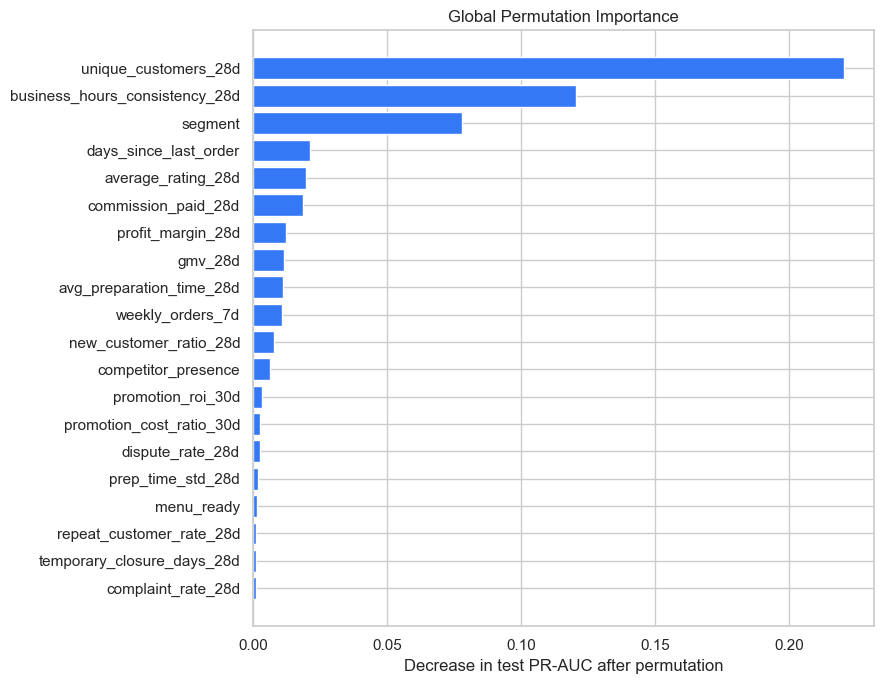

In [53]:
top_importance = permutation_table.head(20).sort_values("importance_mean")
plt.figure(figsize=(9, 7))
plt.barh(top_importance["feature"], top_importance["importance_mean"], color="#3478F6")
plt.xlabel("Decrease in test PR-AUC after permutation")
plt.title("Global Permutation Importance")
plt.tight_layout()
plt.show()

## 5. 模型解释三：SHAP

SHAP 可以回答两类问题：

- Global：哪些变量整体最影响模型？
- Local：为什么某一个商家被判为高风险？

SHAP 值为正表示该变量把预测推向更高的流失风险，为负则把预测推向更低风险。绝对值越大，影响越强。

SHAP 的思路是：把某个预测与模型的基准预测进行比较，再把两者之间的差异分配给各个特征。它解释的是**模型如何使用特征**，不能证明某个因素在业务上导致了流失。

In [54]:
import shap

# 使用已经拟合完成的 Random Forest，并保持与模型训练完全相同的预处理。
forest = fitted_models["random_forest_balanced"]
forest_preprocessor = forest.named_steps["preprocessor"]
forest_model = forest.named_steps["model"]
transformed = forest_preprocessor.transform(test[model_features])
transformed_names = forest_preprocessor.get_feature_names_out()
transformed_frame = pd.DataFrame(transformed, columns=transformed_names)
shap_sample = transformed_frame.sample(
    n=min(300, len(transformed_frame)), random_state=RANDOM_SEED
)

explainer = shap.TreeExplainer(forest_model)
shap_values = explainer(shap_sample)

# 二分类森林可能同时返回 class 0 和 class 1；这里只解释“流失”类别。
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP sample shape:", shap_values.shape)

SHAP sample shape: (300, 63)


### 5.1 Beeswarm Plot：同时看重要性、方向和分布

Beeswarm 图的读法：

- **每一行是一个特征**，按照平均绝对 SHAP 值从高到低排序；
- **每一个点是一条商家记录**；
- 横轴是 SHAP value：越靠右，越把预测推向流失；越靠左，越把预测推向未流失；
- 颜色表示该记录的特征值大小：通常红色代表高值，蓝色代表低值；
- 一行在水平方向越分散，说明这个特征对不同商家的影响差异越大。

例如，如果某特征的红点主要位于右侧，可以描述为“该特征取值较高时，模型通常给出更高的流失风险”。这里仍然是在解释模型行为，而不是证明因果。

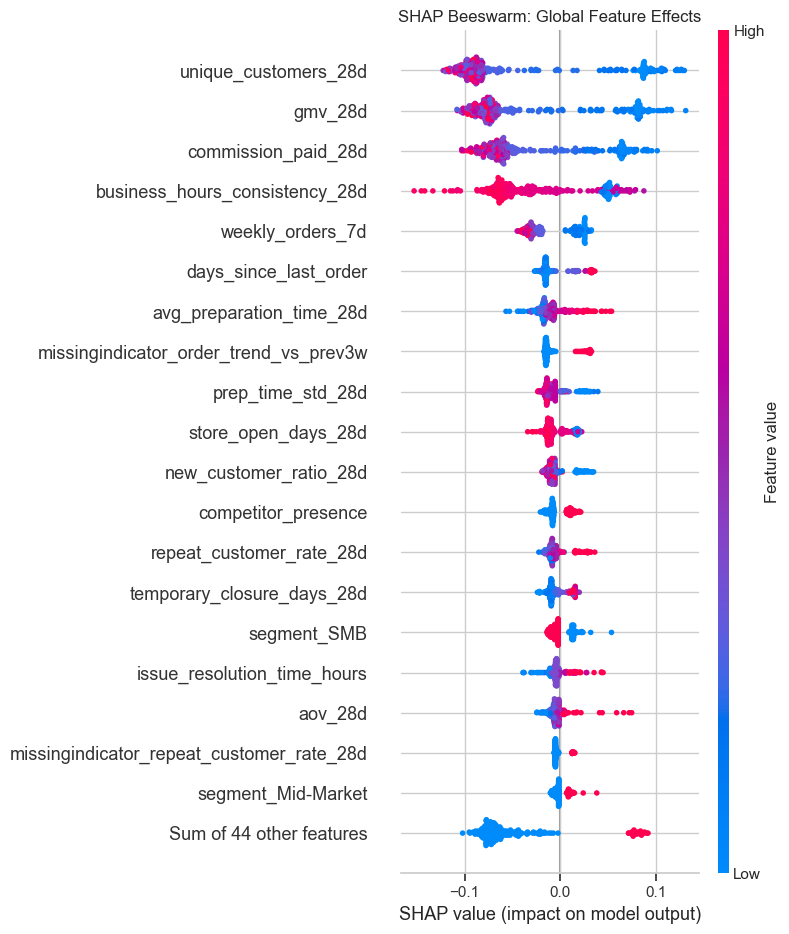

In [55]:
shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.title("SHAP Beeswarm: Global Feature Effects")
plt.tight_layout()
plt.show()

### 5.2 SHAP Scatter Plot：取消率从哪里开始推高流失风险？

`shap.plots.scatter` 更适合深入研究单个特征：

- 横轴是该特征的实际取值；
- 纵轴是该特征对应的 SHAP value；
- 点越高，说明这个特征在该取值下越倾向于提高模型预测的流失风险；
- 如果点的走势不是直线，说明模型学到了非线性关系或阈值；
- 图中的水平虚线是 `SHAP = 0`：点从虚线下方移动到上方，表示该特征的贡献从降低流失预测转为提高流失预测；
- 竖直虚线标记 `cancellation rate = 20%`，帮助观察该参考位置附近的 SHAP value 是否由负转正；
- 横轴下方的灰色分布表示样本集中在哪里。判断潜在拐点时，还要确认拐点两侧是否都有足够样本。


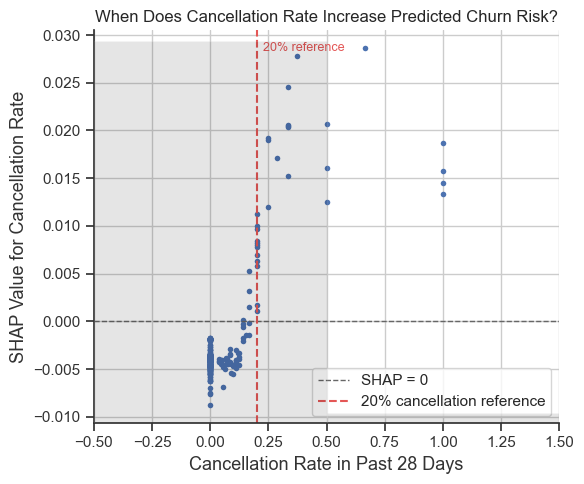

In [56]:
scatter_feature = "numeric__cancellation_rate_28d"
if scatter_feature not in shap_values.feature_names:
    # 兼容不同 sklearn 版本产生的列名前缀。
    scatter_feature = next(
        name for name in shap_values.feature_names
        if name.endswith("cancellation_rate_28d")
    )

shap.plots.scatter(
    shap_values[:, scatter_feature],
    color=None,
    show=False,
)
reference_threshold = 0.20
plt.axhline(0, color="#666666", linestyle="--", linewidth=1, label="SHAP = 0")
plt.axvline(
    reference_threshold,
    color="#E45756",
    linestyle="--",
    linewidth=1.5,
    label="20% cancellation reference",
)
plt.text(
    reference_threshold + 0.025,
    0.97,
    "20% reference",
    color="#E45756",
    transform=plt.gca().get_xaxis_transform(),
    va="top",
    fontsize=9,
)
plt.xlabel("Cancellation Rate in Past 28 Days")
plt.ylabel("SHAP Value for Cancellation Rate")
plt.title("When Does Cancellation Rate Increase Predicted Churn Risk?")
plt.legend(loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

### 5.3 PDP：取消率变化时，模型的平均预测风险如何变化？

PDP（Partial Dependence Plot，部分依赖图）会依次把所有 Test 样本的取消率设置为同一个值，同时保留其他特征原来的取值，再计算全体样本的平均预测流失概率。

因此，这张图回答的是：**在当前模型中，如果取消率从低到高变化，平均预测风险会如何变化？** 它展示的是模型响应，不是取消率对真实流失的因果效应。底部短线表示 Test data 中取消率实际出现的位置；样本非常稀少的区间要谨慎解释。

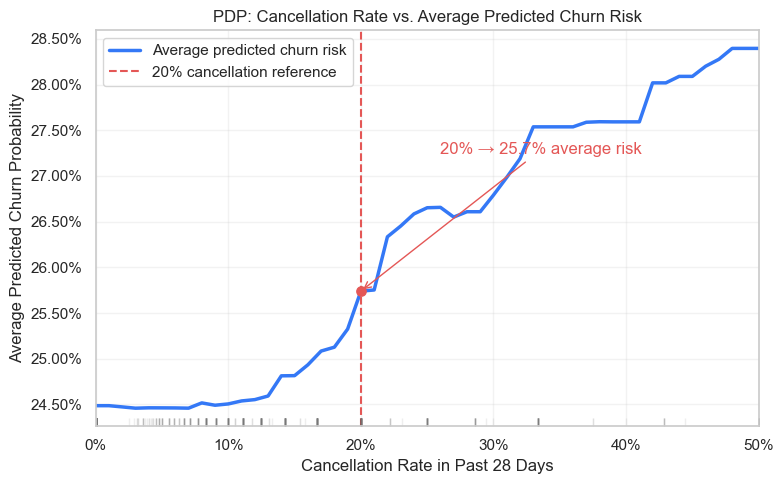

,cancellation_rate_28d,average_predicted_churn_risk
0,0.000,0.245
10,0.100,0.245
20,0.200,0.257
30,0.300,0.268
40,0.400,0.276
50,0.500,0.284


In [57]:
# 主要样本集中在 0%～50%；限制展示范围，避免极少数高比率值压缩主图。
pdp_grid = np.linspace(0, 0.50, 51)
pdp_average_risk = []

for cancellation_rate in pdp_grid:
    pdp_data = test[model_features].copy()
    pdp_data["cancellation_rate_28d"] = cancellation_rate
    pdp_average_risk.append(forest.predict_proba(pdp_data)[:, 1].mean())

pdp_result = pd.DataFrame({
    "cancellation_rate_28d": pdp_grid,
    "average_predicted_churn_risk": pdp_average_risk,
})
risk_at_20_percent = np.interp(0.20, pdp_grid, pdp_average_risk)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    pdp_grid, pdp_average_risk,
    color="#3478F6", linewidth=2.5,
    label="Average predicted churn risk",
)
ax.axvline(
    0.20, color="#E45756", linestyle="--", linewidth=1.5,
    label="20% cancellation reference",
)
ax.scatter(
    [0.20], [risk_at_20_percent],
    color="#E45756", s=45, zorder=3,
)
ax.annotate(
    f"20% → {risk_at_20_percent:.1%} average risk",
    xy=(0.20, risk_at_20_percent),
    xytext=(0.26, risk_at_20_percent + 0.015),
    arrowprops={"arrowstyle": "->", "color": "#E45756"},
    color="#E45756",
)
observed_rates = test["cancellation_rate_28d"].dropna()
observed_rates = observed_rates[observed_rates.between(0, 0.50)]
ax.plot(
    observed_rates, np.full(len(observed_rates), 0.01),
    "|", color="#777777", alpha=0.12,
    transform=ax.get_xaxis_transform(),
)
ax.set_xlim(0, 0.50)
ax.set_xlabel("Cancellation Rate in Past 28 Days")
ax.set_ylabel("Average Predicted Churn Probability")
ax.set_title("PDP: Cancellation Rate vs. Average Predicted Churn Risk")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

pdp_result.iloc[::10].round(4)

## 6. 保存关键结果

Notebook 中最值得交付给业务团队的不是所有中间对象，而是：

- cohort 与流失率检查；
- 模型比较表；
- 最终测试指标；
- Top 5% 运营名单；
- 特征解释表。

保存结果也让分析具备可审计性：之后可以追踪某个数字来自哪个 cutoff、哪个模型和哪个阈值。

In [58]:
label_summary.to_csv(NOTEBOOK_OUTPUT_DIR / "label_summary.csv", index=False)
missingness.to_csv(NOTEBOOK_OUTPUT_DIR / "missingness_all_features.csv", index=False)
imputation_plan.to_csv(NOTEBOOK_OUTPUT_DIR / "imputation_plan.csv", index=False)
ablation_comparison.to_csv(NOTEBOOK_OUTPUT_DIR / "high_missing_ablation.csv", index=False)
imbalance_comparison.to_csv(NOTEBOOK_OUTPUT_DIR / "imbalance_method_comparison.csv", index=False)
validation_metrics.to_csv(NOTEBOOK_OUTPUT_DIR / "validation_metrics.csv", index=False)
pd.DataFrame([test_metrics]).to_csv(NOTEBOOK_OUTPUT_DIR / "test_metrics.csv", index=False)
scored_test.to_csv(NOTEBOOK_OUTPUT_DIR / "test_scored_merchants.csv", index=False)
coefficient_table.to_csv(NOTEBOOK_OUTPUT_DIR / "logistic_coefficients.csv", index=False)
permutation_table.to_csv(NOTEBOOK_OUTPUT_DIR / "permutation_importance.csv", index=False)

print("Saved to:", NOTEBOOK_OUTPUT_DIR.resolve())

Saved to: /Users/luorui/Desktop/职业咨询与求职/导师/上课课件库/小班课/ML - Churn/ML_Project_Uber_Eat_Churn_Prediction/outputs/eda_modeling_notebook


## 总结：一条可靠的建模链路

这次项目最重要的不是记住某个模型 API，而是建立一条可靠的分析链路：

1. **先定义 grain、cutoff 和 label window**，再写特征；
2. **标签必须由五张原始表可复现计算**，不能依赖未知来源的结果表；
3. **EDA 先检查数据是否可信**，再讨论模型；
4. **预处理只在 Train 上学习**，Pipeline 是防止泄漏的重要工具；
5. **类别不平衡没有固定答案**，class weight、过采样、欠采样和 SMOTE 必须在原始 Validation 比例上比较；
6. **XGBoost 可以学习非线性和交互**，但仍需与简单基准在相同切分上公平比较；
7. **模型选择看 PR-AUC 与 Top-K 业务指标**，不是只看 Accuracy；
8. **Test 只使用一次**，否则最终指标会失去可信度；
9. **解释模型不等于证明因果**，系数、Permutation Importance 和 SHAP 回答的是模型如何使用信息。

**进一步思考：** 如果运营团队的联系容量从 5% 提高到 10%，Recall@Top K 和 Precision@Top K 会怎样变化？阈值又应该如何调整？

# Appendix A：Training Data Validation 与 K-Fold Cross-Validation

## A.1 为什么一次 Train/Validation 切分可能不够？

如果只做一次切分，模型评估可能受到“这一次刚好分到了哪些商家”的影响。Cross-validation 的目的，是让模型在多个不同验证子集上重复接受检查，从而观察：

- 平均表现如何；
- 不同切分之间波动多大；
- 参数是不是只对某一次切分有效；
- 模型是否稳定。

### K-Fold 的基本过程

假设 `K = 5`：

1. 把 Training data 分成 5 份；
2. 第 1 轮用第 1 份验证，其余 4 份训练；
3. 第 2 轮用第 2 份验证，其余 4 份训练；
4. 重复到每一份都做过一次验证；
5. 汇总 5 次指标的平均值和标准差。

每条训练记录通常会参与 `K-1` 次训练和 1 次验证。Cross-validation 只发生在 Training data 内部，最终 Test 仍然不能参与选模型或调参数。

## A.2 K-Fold、Stratified、Group 与 Time-Series 的区别

| 方法 | 如何切分 | 适合场景 | 本项目的风险或用途 |
|---|---|---|---|
| `KFold` | 随机或按顺序分 K 份 | 独立同分布样本 | 同一商家可能同时进入 train fold 和 validation fold |
| `StratifiedKFold` | 每折尽量保持正负类比例 | 类别不平衡分类 | 保持流失率，但仍不能阻止商家重复泄漏 |
| `GroupKFold` | 同一个 group 只能出现在一侧 | 用户、商家、门店重复出现 | 可按 `merchant_id` 隔离，但不保证每折流失率完全一致 |
| `StratifiedGroupKFold` | 同时尽量保持类别比例并隔离 group | 重复实体的分类任务 | 适合在 Training 内做参数搜索 |
| `TimeSeriesSplit` | 只用过去预测未来 | 时间序列、滚动预测 | 保留时间顺序，但不会自动隔离重复商家 |

这个项目同时存在两个问题：

1. 同一个商家有多个 snapshot；
2. 预测目标是未来月份。

因此主评估仍采用前面使用的 **merchant holdout + future validation/test**。在 Training 内做参数初筛时，可以使用 `StratifiedGroupKFold` 防止同一商家跨 fold；最后仍要回到未来月份 Validation 检查时间泛化能力。

In [59]:
cv_method_summary = pd.DataFrame([
    {"method": "KFold", "keeps_class_ratio": False, "separates_merchants": False, "keeps_time_order": False},
    {"method": "StratifiedKFold", "keeps_class_ratio": True, "separates_merchants": False, "keeps_time_order": False},
    {"method": "GroupKFold", "keeps_class_ratio": False, "separates_merchants": True, "keeps_time_order": False},
    {"method": "StratifiedGroupKFold", "keeps_class_ratio": True, "separates_merchants": True, "keeps_time_order": False},
    {"method": "TimeSeriesSplit", "keeps_class_ratio": False, "separates_merchants": False, "keeps_time_order": True},
])
cv_method_summary

,method,keeps_class_ratio,separates_merchants,keeps_time_order
0,KFold,False,False,False
1,StratifiedKFold,True,False,False
2,GroupKFold,False,True,False
3,StratifiedGroupKFold,True,True,False
4,TimeSeriesSplit,False,False,True


In [60]:
# 在 Training data 内演示 4-fold Stratified Group CV。
# groups=merchant_id 确保同一个商家的多个 snapshot 不会横跨同一轮的 train/validation。
group_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_SEED,
)

fold_checks = []
for fold, (fit_index, fold_validation_index) in enumerate(
    group_cv.split(X_train, y_train, groups=train["merchant_id"]),
    start=1,
):
    fit_merchants = set(train.iloc[fit_index]["merchant_id"])
    fold_validation_merchants = set(
        train.iloc[fold_validation_index]["merchant_id"]
    )
    fold_checks.append({
        "fold": fold,
        "fit_rows": len(fit_index),
        "validation_rows": len(fold_validation_index),
        "fit_churn_rate": y_train.iloc[fit_index].mean(),
        "validation_churn_rate": y_train.iloc[fold_validation_index].mean(),
        "merchant_overlap": len(fit_merchants & fold_validation_merchants),
    })

pd.DataFrame(fold_checks)

,fold,fit_rows,validation_rows,fit_churn_rate,validation_churn_rate,merchant_overlap
0,1,2998,1002,0.147,0.158,0
1,2,3000,1000,0.147,0.158,0
2,3,3000,1000,0.148,0.156,0
3,4,3002,998,0.157,0.128,0


## A.3 Cross-validation 的几个常见误区

1. **不是 fold 越多越好。** K 越大，训练次数越多，计算成本越高；常见起点是 5-fold 或 10-fold。
2. **不能先用全量数据做 imputation、scaling 或 SMOTE。** 这些步骤必须位于 Pipeline 内，在每个 training fold 单独 `fit`。
3. **不能让同一商家跨 fold。** 否则模型可能利用商家自身的重复信息。
4. **普通随机 CV 不能替代未来时间验证。** 时间漂移是 churn 模型上线后必须面对的问题。
5. **Test 不是 CV 的一折。** Test 在所有参数和模型确定后才使用一次。

# Appendix B：Hyperparameter Tuning 与 Grid Search

## B.1 Parameter 与 Hyperparameter 的区别

- **Model parameters**：训练过程中从数据学习，例如 Logistic Regression 的系数、树的切分点。
- **Hyperparameters**：训练前由我们设定，例如 `C`、`max_depth`、`learning_rate`。

Hyperparameter tuning 的目标，是在 Training data 内寻找泛化表现较好的配置，而不是寻找 Training score 最高的配置。

## B.2 Grid Search 是什么？

Grid Search 会列出一组候选值，然后尝试它们的所有组合。

例如：

```text
C = [0.1, 1, 10]
class_weight = [None, "balanced"]
```

一共有 `3 × 2 = 6` 组参数。如果使用 5-fold CV，就需要训练 `6 × 5 = 30` 次模型，最后通常还会用最佳参数在完整 Training data 上再拟合一次。

Grid Search 的优点是系统、容易解释；缺点是组合数量增长很快，而且只检查我们事先列出的点。

## B.3 Pipeline 中的参数名称

`GridSearchCV` 使用双下划线定位 Pipeline 中的参数：

- `model__C`：Pipeline 中名为 `model` 的步骤，其参数 `C`；
- `preprocessor__...`：定位预处理步骤内部参数；
- `sampler__sampling_strategy`：定位 imbalanced-learn Pipeline 中的 sampler 参数。

所有预处理都留在 Pipeline 内，Grid Search 每一折都会只使用当轮 training fold 学习 median、scaler、one-hot 和 sampling，避免数据泄漏。

In [61]:
# 一个规模较小、可以实际运行的 Logistic Regression Grid Search。
logistic_tuning_pipeline = Pipeline([
    (
        "preprocessor",
        make_preprocessor(numeric_features, categorical_features, scale=True),
    ),
    (
        "model",
        LogisticRegression(max_iter=3000, random_state=RANDOM_SEED),
    ),
])

logistic_parameter_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__class_weight": [None, "balanced"],
}

logistic_grid_search = GridSearchCV(
    estimator=logistic_tuning_pipeline,
    param_grid=logistic_parameter_grid,
    scoring="average_precision",  # 用 PR-AUC 选参数，而不是 Accuracy。
    cv=group_cv,
    n_jobs=-1,
    return_train_score=True,
)

logistic_grid_search.fit(
    X_train,
    y_train,
    groups=train["merchant_id"],
)

print("Best CV PR-AUC:", round(logistic_grid_search.best_score_, 4))
print("Best parameters:", logistic_grid_search.best_params_)

Best CV PR-AUC: 0.7891
Best parameters: {'model__C': 10.0, 'model__class_weight': 'balanced'}


In [62]:
# Inner CV 找到参数后，仍然要在真正的未来月份 Validation 上检查。
tuned_logistic_validation_metrics, _ = evaluate_model(
    "logistic_grid_search_best",
    logistic_grid_search.best_estimator_,
    X_validation,
    y_validation,
    "future_validation",
)
pd.DataFrame([tuned_logistic_validation_metrics])

,model,split,rows,positive_rate,pr_auc,roc_auc,log_loss,contacted,threshold_at_capacity,precision_at_capacity,recall_at_capacity
0,logistic_grid_search_best,future_validation,2000,0.150,0.785,0.970,0.281,100,0.980,0.810,0.270


## B.4 为什么不直接对 XGBoost 做一个巨大 Grid？

假设每个参数各有 3 个候选值，8 个参数就会产生：

`3⁸ = 6,561` 组配置。

再乘以 5-fold，需要训练 32,805 次模型。Grid Search 很容易变成昂贵而低效的穷举。

实践中常见顺序：

1. 先根据经验设置合理范围；
2. 使用较小 Grid 理解参数方向；
3. 使用 `RandomizedSearchCV` 随机搜索更大的空间；
4. 数据量更大时使用 Optuna、Bayesian optimization 或 early stopping；
5. 最终都必须在固定 Future Validation 上确认。

In [63]:
example_parameter_grids = {
    "logistic": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
    "random_forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 8, 14],
        "model__min_samples_leaf": [4, 8, 16],
        "model__max_features": ["sqrt", 0.5],
    },
    "xgboost": {
        "model__n_estimators": [200, 400],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [3, 4, 6],
        "model__subsample": [0.7, 0.9],
        "model__colsample_bytree": [0.7, 0.9],
    },
}

pd.DataFrame([
    {
        "model": model_name,
        "parameter_combinations": len(list(ParameterGrid(parameter_grid))),
    }
    for model_name, parameter_grid in example_parameter_grids.items()
])

,model,parameter_combinations
0,logistic,8
1,random_forest,36
2,xgboost,72


# Appendix C：三个模型的关键参数

## C.1 Logistic Regression

| 参数 | 作用 | 调大或改变后的典型影响 |
|---|---|---|
| `C` | 正则化强度的倒数 | `C` 越小，正则化越强，系数更接近 0，模型更简单；`C` 越大，更贴合训练数据，也更可能过拟合 |
| `penalty` | 正则化类型 | `l2` 平滑缩小系数；`l1` 可以把部分系数压到 0，形成稀疏模型 |
| `solver` | 数值优化算法 | 不同 solver 支持的 penalty 不同；`liblinear` 适合较小数据，`saga` 支持 l1/l2 和更大数据 |
| `class_weight` | 类别错误权重 | `balanced` 提高少数类影响，可能提升 Recall，但可能降低 Precision 和概率校准 |
| `max_iter` | 最大优化迭代次数 | 太小可能不收敛；调大主要解决收敛，不等于模型一定更好 |
| `random_state` | 随机过程种子 | 用于结果复现，不是需要追求最优的业务参数 |

Logistic Regression 的核心假设是特征与 log-odds 近似线性。标准化数值变量可以让正则化更公平，也让系数更容易比较。

## C.2 Random Forest

### 树模型调参的本质是什么？

树模型调参不是让树越多、越深越好，而是在几件事之间寻找平衡：

- **拟合能力**：模型是否已经学到数据中的主要规律；能力太弱会欠拟合；
- **过拟合风险**：模型是否开始记住训练数据中的偶然噪声；
- **训练速度**：更多、更深的树通常需要更长的训练和预测时间；
- **稳定性**：模型换一批样本后，结果是否仍然接近；
- **复杂度**：模型允许学习多细、多复杂的规则和特征组合；
- **泛化能力**：模型在未来没见过的数据上是否仍然有效。

可以把它简单理解成：模型太简单，重要规律还没学会；模型太复杂，又可能把训练样本中的偶然现象当成规律。调参的目标不是得到最复杂的模型，而是找到在 Validation data 上表现稳定、在未来数据上最可能继续有效的模型。

树的数量控制“综合多少棵树”，树的深度控制“每棵树能学习多复杂的规则”。在 Boosting 模型中，learning rate 还控制“每一棵新树修正前面错误时迈多大一步”。这几个参数通常需要一起调整。

| 参数 | 作用 | 调大或改变后的典型影响 |
|---|---|---|
| `n_estimators` | 树的数量 | 更多树通常降低随机波动，但训练和预测更慢；达到稳定后收益递减 |
| `max_depth` | 单棵树最大深度 | 越深能学习更复杂关系，也更容易过拟合；`None` 表示继续生长直到其他停止条件触发 |
| `min_samples_leaf` | 叶节点最少样本数 | 调大让树更平滑、更稳健；太大可能欠拟合少数类模式 |
| `max_features` | 每次分裂可尝试的特征数 | 越小，树之间差异更大；越大，单棵树更强但树之间更相似 |
| `class_weight` | 类别权重 | `balanced` 或 `balanced_subsample` 提高流失类影响 |
| `bootstrap` | 是否有放回抽样训练每棵树 | Random Forest 通常使用 bootstrap，让不同树看到不同样本 |
| `n_jobs` | 并行 CPU 数 | `-1` 使用可用 CPU；影响速度，不改变模型统计目标 |

Random Forest 通过“很多棵有差异的树取平均”降低单棵决策树的方差。关键是在树的复杂度、树之间的多样性和计算成本之间平衡。

## C.3 XGBoost

在 XGBoost 中，可以先用一个直观类比理解三个核心参数：`n_estimators` 是允许模型修改多少轮，`learning_rate` 是每轮修改多少，`max_depth` 是每轮可以使用多复杂的规则。较小步长通常需要更多树；更深的树能学习更复杂的交互，但也更容易过拟合。

| 参数 | 作用 | 调大或改变后的典型影响 |
|---|---|---|
| `n_estimators` | Boosting 轮数/树的数量 | 更多轮可以继续修正错误，但过多可能过拟合；通常与 learning rate 一起调 |
| `learning_rate` | 每棵新树的贡献步长 | 越小学习越稳健，但通常需要更多树；越大训练更快，也更容易过拟合 |
| `max_depth` | 单棵树最大深度 | 越深可学习更复杂交互，但方差和过拟合风险增加 |
| `min_child_weight` | 子节点所需的最小二阶梯度权重 | 越大越保守，阻止模型为少量样本建立复杂分支 |
| `subsample` | 每轮使用的训练样本比例 | 小于 1 可以增加随机性、缓解过拟合；太小会丢失太多信息 |
| `colsample_bytree` | 每棵树使用的特征比例 | 小于 1 降低特征依赖并增加树的差异；太小可能漏掉关键信号 |
| `gamma` | 新增分裂所需的最小收益 | 越大越保守，只有明显改善损失时才分裂 |
| `reg_alpha` | L1 正则化 | 越大越倾向产生稀疏、保守的叶节点权重 |
| `reg_lambda` | L2 正则化 | 越大越平滑叶节点权重，降低过拟合 |
| `scale_pos_weight` | 正类在损失函数中的权重 | 常用起点为负类数/正类数；可能提升少数类排序，但也可能影响概率校准 |
| `eval_metric` | 训练监控指标 | 分类可使用 `logloss`、`aucpr` 等；最终业务选择仍看统一 Validation 指标 |
| `random_state` | 随机种子 | 保证抽样和建树过程可复现 |
| `n_jobs` | 并行 CPU 数 | 影响运行速度，不是模型质量参数 |

### 参数之间不是独立的

- 较小的 `learning_rate` 通常搭配较大的 `n_estimators`；
- 较大的 `max_depth` 往往需要更强的 `min_child_weight`、`gamma` 或正则化；
- 较小的 `subsample` 和 `colsample_bytree` 可以缓解复杂模型过拟合；
- `scale_pos_weight` 改变类别成本，必须同时检查 PR-AUC、Top-K 和 calibration。

## Appendix 总结：推荐的调参流程

1. 固定最终 Test，不查看；
2. 保留 Future Validation，检查时间泛化；
3. 在 Training 内使用 Group-aware CV；
4. 把 imputation、scaling、one-hot、sampling 和模型全部放进 Pipeline；
5. 先从小而有业务依据的参数范围开始；
6. 用 PR-AUC 做主要 tuning score，同时检查 Top 5% 和 calibration；
7. 在 Future Validation 上确认最佳配置；
8. 所有选择结束后，才在 Test 上评估一次。

Cross-validation 能减少一次随机切分的偶然性，Grid Search 能系统比较候选参数，但它们都不能修复错误的标签、数据泄漏或不合理的 Feature Mart。